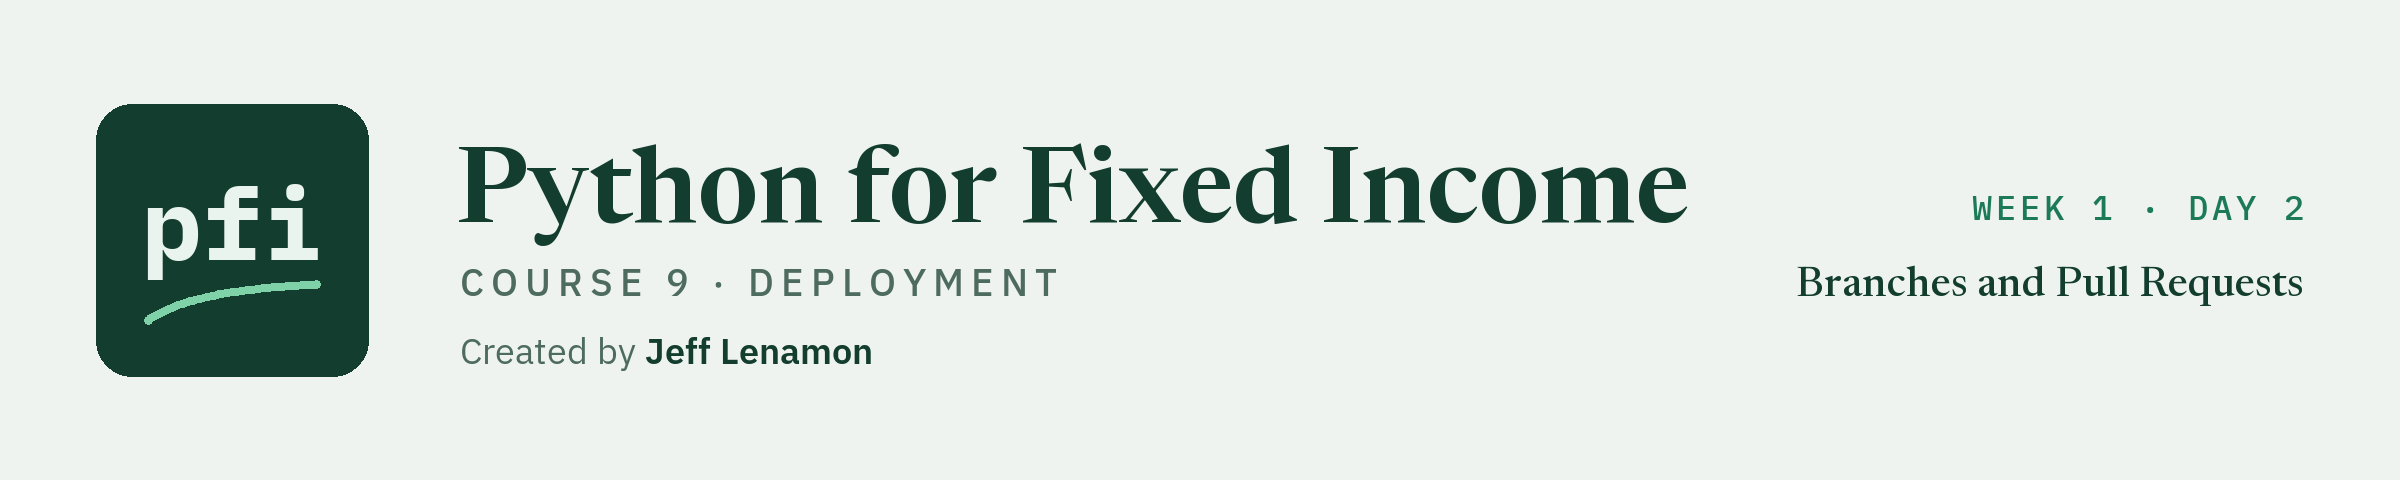

# Branches and Pull Requests

Week 1, Day 2. Today you work on branches beside `main`, merge them two ways, resolve a conflict on purpose, read the course's own pull request on GitHub, and review a change by its diff before anything merges.

**Recorded transcripts:** `course9_transcripts/`, what the platforms printed when the course ran the same steps on its own accounts, recorded once and masked (account names, URLs, ids); shown, never re-run.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course9_deployment/week1/day2/02_branches_and_pull_requests.ipynb)

On day 1 your code got a remote of its own, `remote.git`, and a colleague's clone. Every commit went straight onto `main`. That works for one person on one change. It stops working the moment `main` is what a server runs: from week 2, `main` of a public repo is what Vercel deploys, so a half-finished change on `main` is a half-finished service at a public URL.

**Branches** keep work beside `main` until it is finished, tested, and read by someone else. Today the day's three new functions arrive on three branches, one of them meets a colleague's push, and two of them collide in the same lines of the same file. Then you read a real pull request on GitHub, recorded on the course's own account, and review an AI-written change by its diff.

**The rules for deployed code, as on day 1.** Nothing goes public until `public_scan` is empty. The bonds are synthetic, and a real company appears only as the author of a document. A service returns figures with their as-of date and never a view on any security or rate. Your firm's policy comes first: the free accounts are personal accounts for learning.

**Rows.** No model is fitted or served today, and no cell reaches GitHub. The data are four **recorded transcripts**: what Git and GitHub's command line printed when the course pushed a branch, opened a pull request, read it, and merged it on its throwaway public repo, recorded once and masked.

Today you will:

1. See why `main` is what is deployed, and work beside it.
2. Make a branch, commit on it, push it, and read what it changes with `diff_table`.
3. Merge two ways: a fast-forward, and a merge after a colleague's push.
4. Make a conflict on purpose, read both sides, keep both, and let the tests settle it.
5. Read a pull request on GitHub: a branch plus a conversation.
6. Review a change by its diff before it merges.
7. Name the three ways GitHub merges, and squash the day's module commit.
8. Delete merged branches, here and on the remote.

Q. Set up today's work folder: the thread settings, the quiet-loading settings, the seed, the course's files, and a fresh work folder.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course9_deployment/requirements.txt
NEEDED = {
    "bs4": "beautifulsoup4==4.15.0",
    "fastapi": "fastapi==0.143.0",
    "gradio": "gradio==6.30.0",
    "httpx": "httpx==0.28.1",
    "huggingface_hub": "huggingface-hub==1.33.0",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "joblib": "joblib==1.6.0",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "mcp": "mcp==2.3.0",
    "numpy": "numpy==2.5.3",
    "openai": "openai==3.26.0",
    "agents": "openai-agents==0.23.1",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pydantic": "pydantic==2.13.5",
    "pypdf": "pypdf==6.19.0",
    "pypdfium2": "pypdfium2==5.14.0",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "yaml": "pyyaml==6.0.3",
    "requests": "requests==2.34.2",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "sentence_transformers": "sentence-transformers==6.1.0",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "streamlit": "streamlit==1.65.0",
    "tensorflow": "tensorflow==2.21.0",
    "torch": "torch==2.14.1",
    "transformers": "transformers==5.19.0",
    "uvicorn": "uvicorn==0.54.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

36 packages checked, all present


In [2]:
# today's setup: thread settings, quiet loading, the modules, the seed, the course data, a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, or PyTorch is imported: if you ran another cell first,
# restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# the model libraries print download bars and notices; these lines must run before they are imported
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("torch", "torch"), ("transformers", "transformers"), ("sentence_transformers", "sentence-transformers"), ("openai", "openai"), ("agents", "openai-agents"), ("mcp", "mcp"), ("pydantic", "pydantic"), ("bs4", "beautifulsoup4"), ("dotenv", "python-dotenv"), ("openpyxl", "openpyxl"), ("pytest", "pytest"), ("fastapi", "fastapi"), ("uvicorn", "uvicorn"), ("gradio", "gradio"), ("streamlit", "streamlit"), ("yaml", "pyyaml"), ("joblib", "joblib")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course9_deployment/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "torch": "2.14.1", "transformers": "5.19.0", "sentence-transformers": "6.1.0", "openai": "3.26.0", "openai-agents": "0.23.1", "mcp": "2.3.0", "pydantic": "2.13.5", "pytest": "9.1.1", "fastapi": "0.143.0", "gradio": "6.30.0", "streamlit": "1.65.0"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name].split("+")[0] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "holdings.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course9_02_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["course9_transcripts/day02/git_push_branch.txt", "course9_transcripts/day02/gh_pr_create.txt", "course9_transcripts/day02/gh_pr_view.txt", "course9_transcripts/day02/gh_pr_merge.txt"]
for name in DATA_FILES:
    (work / name).parent.mkdir(parents=True, exist_ok=True)
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, torch 2.14.1, transformers 5.19.0, sentence-transformers 6.1.0, openai 3.26.0, openai-agents 0.23.1, mcp 2.3.0, pydantic 2.13.5, pytest 9.1.1, fastapi 0.143.0, gradio 6.30.0, streamlit 1.65.0
Work folder: pfi_course9_02_4jnw41ky, in your temp folder
Data files from the data folder of the course repo: course9_transcripts/day02/git_push_branch.txt, course9_transcripts/day02/gh_pr_create.txt, course9_transcripts/day02/gh_pr_view.txt, course9_transcripts/day02/gh_pr_merge.txt
SEED = 42


Q. Write the earlier courses' modules today needs, unchanged: `bondmath.py`, `marketdata.py`, `plotkit.py`.

In [3]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


In [4]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100


def slope_bp(curve: pd.DataFrame, short: str, long: str) -> pd.Series:
    """A curve slope in basis points: the long tenor's yield less the short tenor's.

    Units: yields in percent in, bp out. Convention: (curve[long] - curve[short]) x 100, named short then
    long: 2s10s is slope_bp(curve, "2 Yr", "10 Yr"). Positive when the longer yield is higher.
    Excel: =(M2-I2)*100 on the Treasury file opened in Excel, with the 10 Yr in M and the 2 Yr in I.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # long less short, percent to bp
    return ((curve[long] - curve[short]) * 100).rename(f"{short} to {long} slope, bp")


def butterfly_bp(curve: pd.DataFrame, short: str, belly: str, long: str) -> pd.Series:
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than
    the average of the wings. Some desks quote the opposite sign.
    Excel: =(2*K2-I2-M2)*100 on the Treasury file, with the 5 Yr in K.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, belly, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # twice the belly, less each wing, percent to bp
    return ((2 * curve[belly] - curve[short] - curve[long]) * 100).rename(f"{short} {belly} {long} fly, bp")


def fly_weights(dv01_short: float, dv01_belly: float, dv01_long: float) -> tuple[float, float, float]:
    """Face amounts for a DV01-neutral butterfly, per 1 of belly face.

    Units: DV01s in any one unit (price points per 100 of face per bp from bondmath.dv01); weights are face
    per 1 of belly face. Convention: the belly's face is 1; each wing's face is set so its DV01 is half the
    belly's: w_short = 0.5 x dv01_belly / dv01_short and w_long = 0.5 x dv01_belly / dv01_long. With the
    belly on one side and both wings on the other, the DV01s net to zero. Arithmetic, not a position.
    Returns (w_short, 1.0, w_long). Raises ValueError if a DV01 is not positive.
    """
    # a DV01 of zero or less cannot be balanced
    for label, dv01 in (("dv01_short", dv01_short), ("dv01_belly", dv01_belly), ("dv01_long", dv01_long)):
        if dv01 <= 0:
            raise ValueError(f"{label} must be positive, not {dv01}")
    # half the belly's DV01 on each wing
    w_short = 0.5 * dv01_belly / dv01_short
    w_long = 0.5 * dv01_belly / dv01_long
    return w_short, 1.0, w_long


def summary_table(data: pd.DataFrame, as_of, units: dict[str, str], window: int = 252) -> pd.DataFrame:
    """One row per column of `data`: the level and every measure as of one date, from rows on or before it.

    Units: units[column] is "pct" for a series in percent (a yield) or "bp" for a series in bp (a spread,
    slope, or fly). level is in that unit; chg_1d_bp, chg_1w_bp, chg_1m_bp are in bp; zscore has no unit;
    pct_rank is in percent.
    Convention: each column's missing values are dropped and only rows on or before as_of are used, so a later
    row can never change the table. level is the as-of value; chg_1d_bp is the change from the previous
    observation; chg_1w_bp and chg_1m_bp are change_since_bp from as_of - 7 days and as_of - 1 month;
    zscore and pct_rank are rolling_zscore and rolling_percentile_rank over `window` rows, today included.
    Raises ValueError if a column has no unit or a unit other than "pct" or "bp", or the index is not unique
    ascending dates.
    """
    _check_index(data.index, "data")
    as_of = pd.Timestamp(as_of)
    rows = {}
    for column in data.columns:
        # the unit decides whether changes are multiplied by 100
        unit = units.get(column)
        if unit not in ("pct", "bp"):
            raise ValueError(f"units[{column!r}] must be 'pct' or 'bp', not {unit!r}")
        percent_units = unit == "pct"
        # only what was known on the as-of date, missing values dropped
        series = data[column].loc[:as_of].dropna()
        _, level = value_as_of(series, as_of)
        rows[column] = {
            "unit": unit,
            "level": level,
            "chg_1d_bp": change_bp(series, 1, percent_units).iloc[-1],
            "chg_1w_bp": change_since_bp(series, as_of, as_of - pd.Timedelta(days=7), percent_units),
            "chg_1m_bp": change_since_bp(series, as_of, as_of - pd.DateOffset(months=1), percent_units),
            "zscore": rolling_zscore(series, window).iloc[-1],
            "pct_rank": rolling_percentile_rank(series, window).iloc[-1],
        }
    # one row per series
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "series"
    return table


import sqlite3  # a database in one file, from day 11
from contextlib import closing  # closes a connection at the end of a with block, from day 11


def load_tables(db_path: Path, tables: dict[str, Path]) -> dict[str, int]:
    """Write each CSV file to a table of the SQLite database at db_path, and return each table's row count.

    Units: unchanged; dates stay ISO text (YYYY-MM-DD), which SQLite sorts and compares in date order.
    Convention: tables maps a table name to a CSV path; an existing table of that name is replaced. Each
    count is read back from the database with SELECT COUNT(*) and checked against the CSV's rows.
    Raises ValueError for a table name that is not a plain identifier (letters, digits, underscore), and
    RuntimeError if a table's count differs from its CSV's.
    """
    counts = {}
    # sqlite3's own `with` commits but does not close, so closing() closes the file at the end
    with closing(sqlite3.connect(db_path)) as connection:
        for name, csv_path in tables.items():
            # a table name cannot be a ? parameter, so only plain names are allowed
            if not name.isidentifier():
                raise ValueError(f"table name {name!r} must be letters, digits, and underscores")
            frame = pd.read_csv(csv_path)
            frame.to_sql(name, connection, if_exists="replace", index=False)
            connection.commit()
            # read the count back from the database and check it
            count = connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
            if count != len(frame):
                raise RuntimeError(f"table {name} has {count} rows but {Path(csv_path).name} has {len(frame)}")
            counts[name] = count
    return counts


def run_query(db_path: Path, sql: str, params: tuple = ()) -> pd.DataFrame:
    """Run one SQL query against the SQLite database at db_path and return the result.

    Units: as stored. Convention: values go in through ? parameters (`params`), never pasted into the SQL
    text with an f-string. The connection is closed when the query is done.
    Raises FileNotFoundError if db_path does not exist (sqlite3 would otherwise create an empty database).
    """
    if not Path(db_path).is_file():
        raise FileNotFoundError(f"no database file {Path(db_path).name}")
    with closing(sqlite3.connect(db_path)) as connection:
        return pd.read_sql_query(sql, connection, params=params)


def assert_same_rows(left: pd.DataFrame, right: pd.DataFrame, sort_by: list[str]) -> None:
    """Check that two tables hold the same rows, in any order: a SQL result against its pandas equivalent.

    Units: unchanged. Convention: the same column names; both sorted by `sort_by`, index reset, columns in
    left's order; text and whole numbers equal exactly, floats within rtol=1e-12 and atol=1e-9 (SQLite and
    pandas may add in a different order). An integer column on one side may be a float column on the other.
    Raises AssertionError with pandas' message on the first difference.
    """
    # the same columns, whatever their order
    if set(left.columns) != set(right.columns):
        raise AssertionError(f"columns differ: left only {sorted(set(left.columns) - set(right.columns))}, "
                             f"right only {sorted(set(right.columns) - set(left.columns))}")
    # the same order of rows and columns on both sides
    left_sorted = left.sort_values(sort_by).reset_index(drop=True)
    right_sorted = right[list(left.columns)].sort_values(sort_by).reset_index(drop=True)
    pd.testing.assert_frame_equal(left_sorted, right_sorted, check_dtype=False, rtol=1e-12, atol=1e-9)


import json  # an assistant's JSON reply, from day 13


def parse_json_reply(text: str, required: list[str]) -> dict:
    """Read an AI assistant's reply that was asked to answer in JSON, and check it has the fields asked for.

    Units: none. Convention: the whole reply must be one JSON object (json.loads); extra fields are kept.
    Raises ValueError if the text is not JSON, is JSON but not an object, or lacks any field in `required`
    (the message names every missing field).
    """
    # parse the reply; a reply with prose around the JSON fails here
    try:
        reply = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(f"the reply is not valid JSON: {error.msg} at line {error.lineno}, column {error.colno}") from error
    # an object, not a list or a bare number
    if not isinstance(reply, dict):
        raise ValueError(f"the reply is JSON but not an object: it is a {type(reply).__name__}")
    # every field asked for
    missing = [field for field in required if field not in reply]
    if missing:
        raise ValueError(f"the reply is missing {', '.join(missing)}")
    return reply


import base64  # charts embedded in the HTML, from day 14
import html  # safe text in the HTML, from day 14
import io  # a chart written to memory, from day 14

from matplotlib.figure import Figure  # the type of a chart, from day 14

import bondmath  # the book section, from day 14

# the Treasury file's tenor labels and their years
TENOR_YEARS = {"1 Mo": 1 / 12, "1.5 Month": 1.5 / 12, "2 Mo": 2 / 12, "3 Mo": 0.25, "4 Mo": 4 / 12, "6 Mo": 0.5,
               "1 Yr": 1.0, "2 Yr": 2.0, "3 Yr": 3.0, "5 Yr": 5.0, "7 Yr": 7.0, "10 Yr": 10.0, "20 Yr": 20.0,
               "30 Yr": 30.0}
# the slopes (short, long) and flies (short, belly, long) on the snapshot
SLOPES = {"2s10s": ("2 Yr", "10 Yr"), "5s30s": ("5 Yr", "30 Yr"), "3m10y": ("3 Mo", "10 Yr")}
FLIES = {"2s5s10s": ("2 Yr", "5 Yr", "10 Yr"), "5s10s30s": ("5 Yr", "10 Yr", "30 Yr")}
DISCLAIMER = ("This course is educational content created in a personal capacity. Nothing here is investment "
              "advice or a recommendation to buy or sell any security. All portfolio data is synthetic.")
SOURCES = ("Treasury yields: U.S. Department of the Treasury, Daily Treasury Par Yield Curve Rates (public domain). "
           "Credit spreads: course3_synthetic_spreads.csv, synthetic, invented for this course, not ICE, Moody's, "
           "or any index. Book: holdings.csv, a synthetic book of invented issuers.")


def _book_section(book: pd.DataFrame, curve: pd.DataFrame) -> pd.DataFrame:
    """The book's position DV01 and the mechanical change in market value from the day's curve change, by
    sector and by rating bucket, then the total (a helper for snapshot_tables, not part of the API)."""
    settlement_dates = book["as_of_date"].unique()
    if len(settlement_dates) != 1:
        raise ValueError(f"the book must have one as_of_date, not {len(settlement_dates)}")
    settlement = date.fromisoformat(settlement_dates[0])
    # the day's curve change in bp, by tenor in years, for interpolation
    tenors_years = curve["years"].tolist()
    changes_bp = curve["chg_bp"].tolist()
    rows = []
    for bond in book.itertuples():
        maturity = date.fromisoformat(bond.maturity)
        # position DV01 in dollars per bp: DV01 per 100 of face times face / 100
        dv01_usd = bondmath.dv01(settlement, maturity, bond.coupon, bond.yield_pct) * bond.par_held / 100
        # the day's curve change at the bond's maturity, applied to its yield: a what-if, not a forecast
        shift_bp = bondmath.interpolate_yield(bondmath.years_to_maturity(settlement, maturity), tenors_years, changes_bp)
        before = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct)
        after = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct + shift_bp / 100)
        rows.append({"sector": bond.sector, "bucket": bond.rating.rstrip("+-"), "face_usd": bond.par_held,
                     "market_value_usd": bond.market_value, "dv01_usd": dv01_usd,
                     "mv_change_usd": (after - before) * bond.par_held / 100})
    positions = pd.DataFrame(rows)
    sums = {"bonds": ("face_usd", "size"), "face_usd": ("face_usd", "sum"),
            "market_value_usd": ("market_value_usd", "sum"), "dv01_usd": ("dv01_usd", "sum"),
            "mv_change_usd": ("mv_change_usd", "sum")}
    # by sector, then by rating bucket, then the whole book
    by_sector = positions.groupby("sector").agg(**sums).reset_index(names="group").assign(by="sector")
    by_bucket = positions.groupby("bucket").agg(**sums).reset_index(names="group").assign(by="rating bucket")
    total = pd.DataFrame([{"by": "total", "group": "book"} | {k: positions[c].agg(f) for k, (c, f) in sums.items()}])
    table = pd.concat([by_sector, by_bucket, total], ignore_index=True)
    return table[["by", "group", "bonds", "face_usd", "market_value_usd", "dv01_usd", "mv_change_usd"]]


def snapshot_tables(market: pd.DataFrame, book: pd.DataFrame, as_of, units: dict[str, str],
                    window: int = 252) -> dict[str, pd.DataFrame]:
    """The tables of a one-page daily market snapshot for `as_of`, from rows on or before it only.

    Units: yields in percent, spreads, slopes, flies, and changes in bp, dollars in the book table.
    Convention:
    - levels: summary_table of the columns named in `units`;
    - curve: each tenor's yield on as_of and on the previous observation, and the change in bp;
    - slopes_flies: summary_table of 2s10s, 5s30s, 3m10y, 2s5s10s, and 5s10s30s (all in bp);
    - book: the book's position DV01 (bondmath.dv01 at the book's own as_of_date) and the mechanical change
      in market value if each bond's yield moved by the day's change in the par curve, interpolated at its
      maturity with bondmath.interpolate_yield; by sector, by rating bucket, and in total. A what-if.
    Each table's attrs["as_of"] holds the date as YYYY-MM-DD, for the writers.
    Raises ValueError if as_of is not a market date (a date with a row in `market`).
    """
    _check_index(market.index, "market")
    as_of = pd.Timestamp(as_of)
    if as_of not in market.index:
        raise ValueError(f"{as_of.date()} is not a market date: market has no row for it")
    # only what was known on the as-of date
    known = market.loc[:as_of]
    levels = summary_table(known[list(units)], as_of, units, window)

    # the curve on as_of and on the previous observation
    tenors = [column for column in known.columns if column in TENOR_YEARS]
    previous_date = known.index[-2]
    curve = pd.DataFrame({"years": [TENOR_YEARS[t] for t in tenors],
                          "previous_pct": known.loc[previous_date, tenors].to_numpy(),
                          "as_of_pct": known.loc[as_of, tenors].to_numpy()}, index=pd.Index(tenors, name="tenor"))
    curve["chg_bp"] = (curve["as_of_pct"] - curve["previous_pct"]) * 100
    # a tenor with no value on either day is left out; the rest in order of years
    curve = curve.dropna().sort_values("years")

    # slopes and flies, then their summary
    shapes = pd.DataFrame({name: slope_bp(known, short, long) for name, (short, long) in SLOPES.items()}
                          | {name: butterfly_bp(known, *legs) for name, legs in FLIES.items()})
    slopes_flies = summary_table(shapes, as_of, {name: "bp" for name in shapes.columns}, window)

    tables = {"levels": levels, "curve": curve, "slopes_flies": slopes_flies, "book": _book_section(book, curve)}
    for table in tables.values():
        table.attrs["as_of"] = as_of.strftime("%Y-%m-%d")
    return tables


def write_snapshot_html(tables: dict[str, pd.DataFrame], figures: dict[str, Figure], path: Path, title: str) -> Path:
    """Write the snapshot as one self-contained HTML file and return its path.

    Units: as in the tables (numbers shown to 2 decimals). Convention: the title, the as-of date (from the
    tables' attrs, set by snapshot_tables), the disclaimer, each table as DataFrame.to_html, each chart as a
    PNG embedded in base64 (no separate image files), the data sources, and the synthetic label. Describes the
    data; it contains no forecast and no recommendation. Uses no template library.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    parts = [f"<h1>{html.escape(title)}</h1>", f"<p>As of {as_of}.</p>",
             f"<p><em>{html.escape(DISCLAIMER)}</em></p>"]
    # each table, numbers to 2 decimals with thousands separators
    for name, table in tables.items():
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(table.to_html(float_format="{:,.2f}".format))
    # each chart as a PNG held inside the file
    for name, figure in figures.items():
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=100)
        encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(f'<img alt="{html.escape(name)}" src="data:image/png;base64,{encoded}">')
    parts.append(f"<p>{html.escape(SOURCES)}</p>")
    parts.append("<p>The credit spreads and the book are synthetic.</p>")
    page = ("<!DOCTYPE html>\n<html lang=\"en\">\n<head>\n<meta charset=\"utf-8\">\n"
            f"<title>{html.escape(title)}</title>\n</head>\n<body>\n" + "\n".join(parts) + "\n</body>\n</html>\n")
    path = Path(path)
    path.write_text(page, encoding="utf-8", newline="\n")
    return path


def write_snapshot_excel(tables: dict[str, pd.DataFrame], path: Path) -> Path:
    """Write the snapshot tables to one Excel workbook and return its path.

    Units: as in the tables. Convention: pd.ExcelWriter with openpyxl. The first sheet, about, holds the as-of
    date (from the tables' attrs, set by snapshot_tables), the data sources, the synthetic label, and the
    disclaimer, so the workbook describes itself as the HTML page does. Then one sheet per table, named by its
    key, holding the table with its index.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    # what the workbook is, on its first sheet
    about = pd.DataFrame({"value": [as_of, SOURCES, "The credit spreads and the book are synthetic.", DISCLAIMER]},
                         index=pd.Index(["as_of", "sources", "synthetic", "disclaimer"], name="item"))
    path = Path(path)
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        about.to_excel(writer, sheet_name="about")
        for name, table in tables.items():
            table.to_excel(writer, sheet_name=name)
    return path

Writing marketdata.py


In [5]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


Q. Write `deploykit.py` and `test_deploykit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [6]:
%%writefile deploykit.py
"""deploykit: shipping your fixed income code, from a public repo to a public app, and keeping it running.

Written day by day in Python for Fixed Income, Course 9: Deployment.

Conventions, the same in every function:
- A server installs only what its code imports. So this module imports the standard library at the top, FastAPI,
  pydantic, and bondmath (standard library only) from day 6, and everything else (pandas, PyYAML, joblib, requests,
  Gradio, Streamlit, agentkit) inside the functions that need it. A service built from deploykit needs fastapi and
  nothing more.
- Nothing here holds or prints a secret. A scan reports where a key-like string is, its kind, its first three
  characters, and its length, never the value.
- Units are in names: price_per_100 and dv01_per_100 per 100 of face, yield_pct in percent, latency_ms in
  milliseconds, sizes in bytes or in MB of 1024 x 1024 bytes, money in US dollars.
- Every served figure states its as-of date. A service returns, refuses, and logs; nothing here is a view on any
  security, issuer, or rate.
"""
from __future__ import annotations  # type hints are read as text, so pandas is imported only where it is used

import re  # the key, email, and address patterns
import subprocess  # running git
from pathlib import Path

# printed by a live-deploy cell when no deployment of your own is set: the cell then does nothing
NO_DEPLOY_MESSAGE = ("No deployment of your own is set in my_bondmath\\.env (MY_SERVICE_URL, MY_SPACE_ID, or HF_TOKEN "
                     "not loaded), so this cell does nothing. After your own deploy, add the line and run it again.")
# what a masked transcript puts in place of each private item
MASKS = {"name": "student", "team": "student-projects", "email": "student@example.com", "id": "<id>", "ip": "<ip>",
         "host": "student"}
# the only email address the course's files and outputs may hold
ALLOWED_EMAIL = "student@example.com"
# key-like strings, each with a minimum length after its prefix so a word in prose does not trip it
KEY_PATTERNS = {
    "sk-or-": re.compile(r"\bsk-or-[A-Za-z0-9-]{8,}"),
    "sk-": re.compile(r"\bsk-(?!or-)[A-Za-z0-9_-]{16,}"),
    "hf_": re.compile(r"\bhf_[A-Za-z0-9]{16,}"),
    "ghp_": re.compile(r"\bghp_[A-Za-z0-9]{16,}"),
    "github_pat_": re.compile(r"\bgithub_pat_[A-Za-z0-9_]{16,}"),
    "vercel_": re.compile(r"\bvercel_[A-Za-z0-9]{16,}"),
    "Bearer ": re.compile(r"\bBearer\s+[A-Za-z0-9._~+/-]{12,}"),
}
_EMAIL = re.compile(r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}")
_IPV4 = re.compile(r"\b(?:\d{1,3}\.){3}\d{1,3}\b")
_PLATFORM_HOST = re.compile(r"\b[a-z0-9][a-z0-9-]*\.(vercel\.app|hf\.space)\b", re.IGNORECASE)
_PLATFORM_ID = re.compile(r"\b(?:dpl|prj|team)_[A-Za-z0-9]{6,}\b")
# Vercel's ids printed without a prefix: a deployment in an inspect address (vercel.com/<team>/<project>/<id>) or in
# "deployment (<id>)", a deployment or project in the CLI's JSON, and a request id (letters and digits, a 13-digit
# time in milliseconds, hexadecimal)
_LONG_ID = r"(?=[A-Za-z0-9]*\d)[A-Za-z0-9]{20,}"
_VERCEL_INSPECT = re.compile(r"(vercel\.com/[^/\s]+/[^/\s]+/)" + _LONG_ID + r"\b")
_VERCEL_DEPLOYMENT = re.compile(r"(deployment \()" + _LONG_ID + r"(\))")
_VERCEL_JSON_ID = re.compile(r'("(?:deploymentId|projectId)": ?")[A-Za-z0-9_]{12,}(")')
_VERCEL_REQUEST = re.compile(r"\b[a-z0-9]{3,}-\d{13}-[0-9a-f]{8,}\b")
# a file that holds environment values; .env.example holds names only and may be published
_ENV_FILE = re.compile(r"^\.env(?!\.example$)")
MB = 1024 * 1024


def run_git(folder, *args: str) -> str:
    """Run one git command in a folder and return what it printed.

    Inputs: folder, the repository's folder; args, the command's words, for example "log", "--oneline", "-3".
    Output: git's standard output as text.
    Convention: the same as typing git -C folder ... in PowerShell. Raises RuntimeError with git's own message
    (its standard error) when the command fails, so a failed push or merge is never silent.
    """
    result = subprocess.run(["git", "-C", str(folder), *args], capture_output=True, text=True, encoding="utf-8")
    if result.returncode != 0:
        raise RuntimeError(f"git {' '.join(args)} failed: {result.stderr.strip()}")
    return result.stdout


def _hidden(value: str) -> str:
    """How a scan names a match without showing it: its first three characters and its length."""
    return f"starts {value[:3]!r}, {len(value)} characters"


def _text_of(path: Path) -> str | None:
    """A file's text, or None for a binary file (one that holds a zero byte)."""
    data = path.read_bytes()
    if b"\x00" in data[:8192]:
        return None
    return data.decode("utf-8", errors="replace")


def _files(folder: Path) -> list[Path]:
    """Every file under a folder, at any depth, without Git's own .git folder, in a fixed order."""
    return sorted(p for p in folder.rglob("*") if p.is_file() and ".git" not in p.relative_to(folder).parts)


def public_scan(folder, max_mb: float = 5.0):
    """Everything in a folder that must not go public, one row per problem.

    Inputs: folder, the folder you are about to push to a public repo; max_mb, the largest file allowed, in MB of
    1024 x 1024 bytes.
    Output: a DataFrame with columns file (relative to the folder), line (0 for the whole file), kind, and detail.
    Kinds: env_file (a .env file at any depth; .env.example, which holds names only, is allowed), key_like (a match
    of KEY_PATTERNS), email (any address but student@example.com), large_file. Empty means safe to publish.
    Convention: the detail never holds a matched value, only its first three characters and its length. Git's .git
    folder is not scanned (its history is checked by what you commit, not by this scan).
    """
    import pandas as pd

    folder = Path(folder)
    rows = []
    for path in _files(folder):
        name = path.relative_to(folder).as_posix()
        if _ENV_FILE.match(path.name):
            rows.append({"file": name, "line": 0, "kind": "env_file", "detail": "an environment file; never published"})
        size = path.stat().st_size
        if size > max_mb * MB:
            rows.append({"file": name, "line": 0, "kind": "large_file",
                         "detail": f"{size / MB:.1f} MB, over {max_mb:g} MB (MB = 1024 x 1024 bytes)"})
        text = _text_of(path)
        if text is None:
            continue
        for number, line in enumerate(text.splitlines(), start=1):
            for kind, pattern in KEY_PATTERNS.items():
                for found in pattern.findall(line):
                    rows.append({"file": name, "line": number, "kind": "key_like",
                                 "detail": f"{kind} pattern, {_hidden(found)}"})
            for found in _EMAIL.findall(line):
                if found.lower() != ALLOWED_EMAIL:
                    rows.append({"file": name, "line": number, "kind": "email", "detail": f"an address, {_hidden(found)}"})
    return pd.DataFrame(rows, columns=["file", "line", "kind", "detail"])


def mask_transcript(text: str, names: list[str]) -> str:
    """A terminal transcript with every private item replaced by the course's masks, safe to share.

    Inputs: text, what a command printed; names, the account names, team slugs, and other words to hide (read on
    the machine that ran the command, never written to a file).
    Output: the text with each name (any case) as "student", every email but student@example.com as
    student@example.com, each IPv4 address as <ip>, the host of every *.vercel.app and *.hf.space address as
    student, and Vercel's ids as <id>: deployment, project, and team ids (dpl_..., prj_..., team_...), the ids the
    CLI prints without a prefix (an inspect address's last part, "deployment (...)", deploymentId and projectId in
    its JSON), and request ids (for example abc12-1791807391930-0123abcd).
    Convention: longer names are replaced first, so a team slug that holds a user name is masked whole.
    """
    for name in sorted((n for n in names if n), key=len, reverse=True):
        text = re.sub(re.escape(name), MASKS["name"], text, flags=re.IGNORECASE)
    text = _EMAIL.sub(lambda m: m.group(0) if m.group(0).lower() == ALLOWED_EMAIL else MASKS["email"], text)
    text = _IPV4.sub(MASKS["ip"], text)
    text = _PLATFORM_HOST.sub(lambda m: f"{MASKS['host']}.{m.group(1).lower()}", text)
    text = _VERCEL_INSPECT.sub(lambda m: m.group(1) + MASKS["id"], text)
    text = _VERCEL_DEPLOYMENT.sub(lambda m: m.group(1) + MASKS["id"] + m.group(2), text)
    text = _VERCEL_JSON_ID.sub(lambda m: m.group(1) + MASKS["id"] + m.group(2), text)
    text = _VERCEL_REQUEST.sub(MASKS["id"], text)
    return _PLATFORM_ID.sub(MASKS["id"], text)


def show_transcript(path, max_lines: int = 40) -> None:
    """Print a masked transcript the course recorded: one line saying what it is, the command, then the text.

    Inputs: path, a file of data/course9_transcripts/dayNN/; max_lines, the most lines of text to print.
    Output: none; prints. A longer text is cut, and the cut is stated with the number of lines not shown.
    Convention: the file's first three lines are its header (recorded:, command:, masked:).
    """
    lines = Path(path).read_text(encoding="ascii").splitlines()
    header = dict(line.split(": ", 1) for line in lines[:3])
    body = lines[3:]
    print(f"Recorded {header['recorded']} on the course's own account; account names, URLs, and ids masked to "
          f"`student`.")
    print(f"> {header['command']}")
    for line in body[:max_lines]:
        print(line)
    if len(body) > max_lines:
        print(f"[... {len(body) - max_lines} more lines not shown]")

Writing deploykit.py


In [7]:
%%writefile test_deploykit.py
"""Tests for deploykit.py. Run in the folder that holds deploykit.py and the earlier modules:
python -m pytest -q test_deploykit.py

The tests use small inline data, temporary folders, a bare repository as a remote, a fake clock, and the ASGI test
client: never a course data file but the ones named, never the network, never a port but the one real server's,
and never a key. Every planted key is fake and built from pieces, so no file of the course holds a key-like string.
"""
import pytest

import deploykit

# a fake key of each kind, built from pieces at run time
FAKE_OPENROUTER = "sk-or-" + "FAKE" * 3
FAKE_HF = "hf" + "_" + "Fake" * 6
# an address that is not the course's, built from pieces so no file of the course holds one
OTHER_EMAIL = "someone" + "@" + "mail.example.org"


def test_run_git_raises_with_stderr(tmp_path):
    deploykit.run_git(tmp_path, "init", "-q")
    with pytest.raises(RuntimeError, match="git log failed"):
        deploykit.run_git(tmp_path, "log")


def test_public_scan_finds_env_file(tmp_path):
    (tmp_path / ".env").write_text("HF_TOKEN=\n")
    (tmp_path / ".env.example").write_text("HF_TOKEN=\n")
    (tmp_path / "bondmath.py").write_text("x = 1\n")
    found = deploykit.public_scan(tmp_path)
    assert found[["file", "kind"]].values.tolist() == [[".env", "env_file"]]


def test_public_scan_finds_key_like_without_printing_it(tmp_path):
    (tmp_path / "config").mkdir()
    (tmp_path / "config" / "settings.py").write_text(f'TOKEN = "{FAKE_HF}"\nKEY = "{FAKE_OPENROUTER}"\n')
    found = deploykit.public_scan(tmp_path)
    assert found["kind"].tolist() == ["key_like", "key_like"] and found["line"].tolist() == [1, 2]
    shown = found.to_string()
    assert FAKE_HF not in shown and FAKE_OPENROUTER not in shown and f"{len(FAKE_HF)} characters" in shown


def test_public_scan_allows_student_email(tmp_path):
    (tmp_path / "README.md").write_text(f"Questions: student@example.com\nAuthor: {OTHER_EMAIL}\n")
    found = deploykit.public_scan(tmp_path)
    assert found[["line", "kind"]].values.tolist() == [[2, "email"]]
    assert "someone" not in found.to_string()


def test_public_scan_large_file(tmp_path):
    (tmp_path / "big.bin").write_bytes(b"\x00" * (deploykit.MB + 1))
    found = deploykit.public_scan(tmp_path, max_mb=1.0)
    assert found[["file", "kind"]].values.tolist() == [["big.bin", "large_file"]]
    assert deploykit.public_scan(tmp_path, max_mb=2.0).empty


def test_mask_transcript_names_emails_hosts():
    raw = (f"To https://github.com/DeskUser/pfi-deploy-demo.git by {OTHER_EMAIL} from 203.0.113.7\n"
           "Production: https://pfi-bond-service-a1b2c3-deskusers-projects.vercel.app (dpl_AbCdEf123456)\n"
           "Space: https://deskuser-pfi-desk-brief.hf.space student@example.com\n")
    masked = deploykit.mask_transcript(raw, ["deskusers-projects", "deskuser"])
    assert "deskuser" not in masked.lower() and OTHER_EMAIL not in masked and "203.0.113.7" not in masked
    assert "dpl_" not in masked
    assert "github.com/student/pfi-deploy-demo.git" in masked and "student@example.com" in masked
    assert "https://student.vercel.app" in masked and "https://student.hf.space" in masked
    assert "<ip>" in masked and "<id>" in masked


def test_mask_transcript_vercel_ids_without_prefix():
    deployment = "8XyZ" + "aB3dE5fG7hJ9kL2mN4pQ6rS"
    request = "abc12-" + "1791807391930" + "-0123abcd"
    raw = (f"Inspect https://vercel.com/deskusers-projects/pfi-bond-service/{deployment}\n"
           f"Restored build cache from previous deployment ({deployment})\n"
           f'{{"id":"{request}","deploymentId":"{deployment}","projectId":"{deployment}"}}\n'
           "Read https://vercel.com/docs/functions/runtimes/python\n")
    masked = deploykit.mask_transcript(raw, ["deskusers-projects"])
    assert deployment not in masked and request not in masked
    assert masked.splitlines() == ["Inspect https://vercel.com/student/pfi-bond-service/<id>",
                                   "Restored build cache from previous deployment (<id>)",
                                   '{"id":"<id>","deploymentId":"<id>","projectId":"<id>"}',
                                   "Read https://vercel.com/docs/functions/runtimes/python"]

Writing test_deploykit.py


Q. Import the modules.

In [8]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import bondmath
import marketdata
import deploykit

# reload reads the file again, so that running this cell after a change picks up the change
importlib.reload(deploykit)

# the functions defined in deploykit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(deploykit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "deploykit" and not name.startswith("_")
             and not isinstance(obj, type)]
print(f"deploykit functions: {len(functions)}")

deploykit functions: 4


Q. Import `plotkit`, Course 4's chart and table helpers (you read this module; you do not write it), and set the course's chart style.

In [9]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The setup cell is day 1's. Today it copies the four transcripts this notebook reads, writes the earlier modules unchanged, and `deploykit.py` and `test_deploykit.py` as they stood at the end of day 1: four functions, six tests.

Q. Rebuild day 1's repository: the work folder with one commit, the bare remote `remote.git` inside it, and a colleague's clone.

In [10]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [11]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course9_02_4jnw41ky and nowhere else


In [12]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
.env
course9_transcripts/
remote.git/
colleague/

Writing .gitignore


In [13]:
# day 1's state in one cell; -q keeps paths and hashes out of the output
!git -C "{work}" add .gitignore bondmath.py marketdata.py deploykit.py test_deploykit.py
!git -C "{work}" commit -q -m "deploykit day 1: run_git, public_scan, mask_transcript, show_transcript, 7 tests"
!git -C "{work}" init --bare -q -b main remote.git
!git -C "{work}" remote add origin remote.git
!git -C "{work}" push -q -u origin main
!git -C "{work}" clone -q remote.git colleague
!git -C "{work}" log --oneline

12da7fd deploykit day 1: run_git, public_scan, mask_transcript, show_transcript, 7 tests


In [14]:
# the guard: the remote must be a bare repository inside the work folder, or the notebook stops
remote = work / "remote.git"
assert remote.resolve().is_relative_to(work.resolve()), "the remote is not inside the work folder"
assert deploykit.run_git(remote, "rev-parse", "--is-bare-repository").strip() == "true", "remote.git is not bare"

# the colleague's clone gets the course's Git settings, so their commits carry the course's name and email
colleague = work / "colleague"
for setting in (["user.name", "Course Colleague"], ["user.email", "student@example.com"], ["core.autocrlf", "false"],
                ["commit.gpgsign", "false"]):
    deploykit.run_git(colleague, "config", *setting)
print(f"work folder: {deploykit.run_git(work, 'status', '-sb').strip()}")
print(f"colleague:   {deploykit.run_git(colleague, 'status', '-sb').strip()}")

work folder: ## main...origin/main
?? plotkit.py
colleague:   ## main...origin/main


* One commit, on `main`, on the remote, and in the clone, level everywhere. The colleague commits as `Course Colleague` with the course's one email address, so their commits are told apart by name.

## 2.1 Why Branches

A **branch** is a name for a line of commits. `main` is the one every repository starts with, and in this course it means one thing: **`main` is what is deployed**. From day 3 GitHub runs the tests on it, and from day 7 Vercel serves whatever `main` holds. So nothing goes onto `main` unfinished. Work happens on a branch beside it; when the work is finished and tested, the branch is merged into `main`, and then deleted.

Q. Which branches does the work folder have, and which one are you on?

In [15]:
!git -C "{work}" branch
!git -C "{work}" status -sb

* main


## main...origin/main
?? plotkit.py


* One branch, `main`, marked `*` because it is checked out: its files are the ones in the folder. `status -sb` adds that `main` tracks `origin/main` and nothing lies between them. From here every `status` also lists `?? plotkit.py`: Course 4's helper module, written to the work folder and never committed.

## 2.2 A Branch of Your Own

Q. Start a branch for the first function of the day, `diff_table`, and switch to it.

In [16]:
# switch -c makes the branch where you are and switches to it; -q keeps Git's message off stderr
!git -C "{work}" switch -q -c diff-table
!git -C "{work}" branch

* diff-table
  main


* `* diff-table`: the folder now follows the new branch. It starts with the same commit as `main`, so nothing has changed yet. A branch costs nothing: it is a name pointing at a commit.

Q. On the branch, add `diff_table` and its test.

In [17]:
%%writefile -a deploykit.py


def diff_table(folder, base: str, head: str):
    """What a change adds and removes, file by file: the table a reviewer reads before the diff itself.

    Inputs: folder, the repository; base and head, two commits, branches, or tags (for example "main" and
    "fix-day-count").
    Output: a DataFrame with columns file, added, removed (lines), from git diff --numstat base head. A binary
    file shows 0 and 0.
    """
    import pandas as pd

    rows = []
    for line in run_git(folder, "diff", "--numstat", base, head).splitlines():
        added, removed, name = line.split("\t", 2)
        rows.append({"file": name, "added": int(added) if added != "-" else 0,
                     "removed": int(removed) if removed != "-" else 0})
    return pd.DataFrame(rows, columns=["file", "added", "removed"])

Appending to deploykit.py


In [18]:
%%writefile -a test_deploykit.py


def make_repo(folder):
    """A repository on branch main with the course's Git settings and one commit of notes.txt."""
    deploykit.run_git(folder, "init", "-q", "-b", "main")
    deploykit.run_git(folder, "config", "user.name", "Course Student")
    deploykit.run_git(folder, "config", "user.email", "student@example.com")
    deploykit.run_git(folder, "config", "core.autocrlf", "false")
    (folder / "notes.txt").write_text("one\ntwo\nthree\n")
    deploykit.run_git(folder, "add", "notes.txt")
    deploykit.run_git(folder, "commit", "-q", "-m", "Start")
    return folder


def commit(folder, name, text, message):
    (folder / name).write_text(text)
    deploykit.run_git(folder, "add", name)
    deploykit.run_git(folder, "commit", "-q", "-m", message)


def test_diff_table_counts(tmp_path):
    make_repo(tmp_path)
    deploykit.run_git(tmp_path, "switch", "-q", "-c", "change")
    commit(tmp_path, "notes.txt", "one\n2\nthree\nfour\n", "Edit notes")
    table = deploykit.diff_table(tmp_path, "main", "change")
    assert table.values.tolist() == [["notes.txt", 2, 1]]

Appending to test_deploykit.py


* `diff_table(folder, base, head)` reads `git diff --numstat base head` and returns one row per file: `file`, `added`, `removed`, in lines. It is the table a reviewer reads before the diff itself: which files a change touches, and how much.
* The tests file gains two helpers every day 2 test uses: `make_repo` makes a repository on `main` with one commit of `notes.txt`, and `commit` writes a file and commits it. Then `test_diff_table_counts`: one line changed and one added gives 2 added and 1 removed.

Q. Reload the module and run the tests.

In [19]:
importlib.reload(deploykit)
print(f"diff_table in deploykit: {hasattr(deploykit, 'diff_table')}")

diff_table in deploykit: True


In [20]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_deploykit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........                                                                 [100%]
8 passed in 1.08s



* `8 passed`: day 1's 7 and the new one.

Q. Commit on the branch, and push the branch to the remote. What does Git print?

In [21]:
!git -C "{work}" add deploykit.py test_deploykit.py
!git -C "{work}" commit -q -m "Add diff_table, with its test"
!git -C "{work}" log --oneline

11b5a9c Add diff_table, with its test
12da7fd deploykit day 1: run_git, public_scan, mask_transcript, show_transcript, 7 tests


In [22]:
# push the branch, and set it to track its copy on the remote
pushed = subprocess.run(["git", "-C", str(work), "push", "-u", "origin", "diff-table"], capture_output=True,
                        text=True, check=True)
print(pushed.stdout + pushed.stderr)

branch 'diff-table' set up to track 'origin/diff-table'.
To remote.git
 * [new branch]      diff-table -> diff-table



* Two commits on `diff-table`, the newest first. `* [new branch]      diff-table -> diff-table`: the remote now has a branch of the same name. `main` on the remote has not moved.

Q. What does the branch change against `main`, file by file?

In [23]:
changes = deploykit.diff_table(work, "main", "diff-table")
print(changes.to_string(index=False))
print(f"lines added: {changes['added'].sum()}; removed: {changes['removed'].sum()}")

             file  added  removed
     deploykit.py     18        0
test_deploykit.py     26        0
lines added: 44; removed: 0


Q. Draw it: lines added and removed, file by file.

,added,removed
file,,
deploykit.py,18,0
test_deploykit.py,26,0


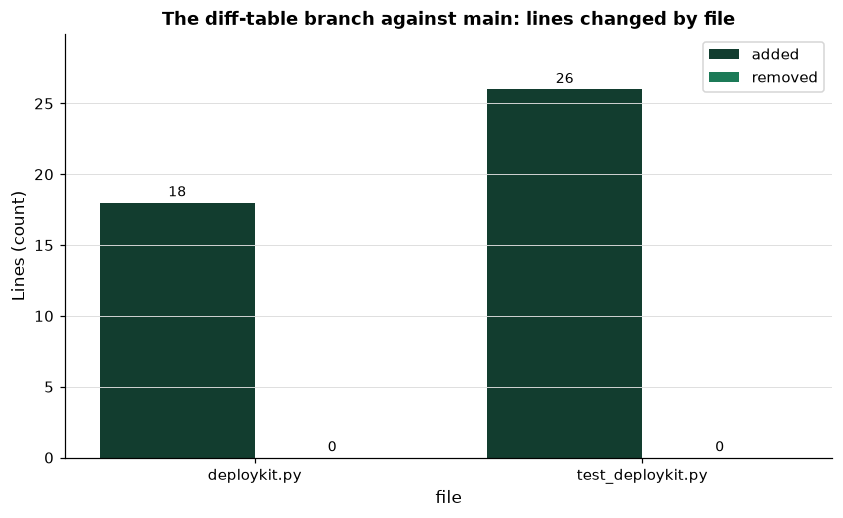

In [24]:
# one row per changed file, a bar for the lines added and a bar for the lines removed
by_file = changes.set_index("file")
display(plotkit.styled(by_file, [], "Lines the diff-table branch changes against main, by file"))
ax = plotkit.bars(by_file, "The diff-table branch against main: lines changed by file", "Lines (count)", fmt="{:,.0f}")
# bars leaves no room above the tallest bar, so make some
ax.set_ylim(0, by_file.to_numpy().max() * 1.15)
plt.show()

* Both files grow and neither shrinks: the added bars stand and the removed bars are zero. Excel's clustered column chart draws the same two columns.

In [25]:
# -a lists the remote's branches too, as origin/<name>
!git -C "{work}" branch -a

* diff-table
  main
  remotes/origin/diff-table
  remotes/origin/main


* Two files, lines added and none removed: the change adds a function and its test and touches nothing else. That is what a reviewer wants to see first.
* `remotes/origin/diff-table` and `remotes/origin/main`: your copy of what the remote holds, as of the last push or fetch.

## 2.3 Two Kinds of Merge

A **merge** brings one branch's commits into another. When the branch you merge into has not moved since the other branch started, Git just moves it forward: a **fast-forward**, no new commit. When both have moved, Git makes a **merge commit** with two parents.

Q. Merge `diff-table` into `main`, fast-forward only, and push `main`.

In [26]:
!git -C "{work}" switch -q main
!git -C "{work}" merge -q --ff-only diff-table
!git -C "{work}" push -q
!git -C "{work}" log --oneline

11b5a9c Add diff_table, with its test
12da7fd deploykit day 1: run_git, public_scan, mask_transcript, show_transcript, 7 tests


* `main` now has the same two commits as `diff-table`: it moved forward, and no merge commit was made. `--ff-only` makes Git refuse anything else, which is the safe default for `main`.

Q. Start a second branch, `branch-table`, add `branch_table` and its test, and commit.

In [27]:
!git -C "{work}" switch -q -c branch-table

In [28]:
%%writefile -a deploykit.py


def branch_table(folder):
    """Every local branch beside main: its last commit's subject, and how far it is ahead of and behind main.

    Input: folder, the repository (it must have a branch named main).
    Output: a DataFrame with columns branch, last_subject, ahead (commits on the branch not on main), behind
    (commits on main not on the branch), one row per branch in name order, main itself included (0 and 0).
    """
    import pandas as pd

    rows = []
    for branch in sorted(run_git(folder, "for-each-ref", "--format=%(refname:short)", "refs/heads").split()):
        subject = run_git(folder, "log", "-1", "--format=%s", branch).strip()
        behind, ahead = run_git(folder, "rev-list", "--left-right", "--count", f"main...{branch}").split()
        rows.append({"branch": branch, "last_subject": subject, "ahead": int(ahead), "behind": int(behind)})
    return pd.DataFrame(rows, columns=["branch", "last_subject", "ahead", "behind"])

Appending to deploykit.py


In [29]:
%%writefile -a test_deploykit.py


def test_branch_table_ahead_behind(tmp_path):
    make_repo(tmp_path)
    deploykit.run_git(tmp_path, "switch", "-q", "-c", "feature")
    commit(tmp_path, "a.txt", "a\n", "Add a")
    commit(tmp_path, "b.txt", "b\n", "Add b")
    deploykit.run_git(tmp_path, "switch", "-q", "main")
    commit(tmp_path, "c.txt", "c\n", "Add c on main")
    table = deploykit.branch_table(tmp_path).set_index("branch")
    assert table.loc["feature", ["ahead", "behind"]].tolist() == [2, 1]
    assert table.loc["feature", "last_subject"] == "Add b"
    assert table.loc["main", ["ahead", "behind"]].tolist() == [0, 0]

Appending to test_deploykit.py


In [30]:
importlib.reload(deploykit)
print(f"branch_table in deploykit: {hasattr(deploykit, 'branch_table')}")

branch_table in deploykit: True


In [31]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_deploykit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........                                                                [100%]
9 passed in 1.95s



In [32]:
!git -C "{work}" add deploykit.py test_deploykit.py
!git -C "{work}" commit -q -m "Add branch_table, with its test"

* `branch_table(folder)` lists every local branch with its last commit's subject and two counts against `main`: **ahead**, commits on the branch that `main` lacks, and **behind**, commits on `main` that the branch lacks. `9 passed`.

Q. Meanwhile, on the colleague's laptop: they pull `main`, ignore the server's log files, commit, and push.

In [33]:
# the colleague's side: run_git is git -C for their folder
deploykit.run_git(colleague, "pull", "-q", "--ff-only")
with open(colleague / ".gitignore", "a", encoding="utf-8") as f:
    f.write("*.log\n")
deploykit.run_git(colleague, "commit", "-q", "-am", "Ignore server logs")
deploykit.run_git(colleague, "push", "-q")
print(deploykit.run_git(colleague, "log", "--format=%s by %an", "-1"))

Ignore server logs by Course Colleague



Q. You merge `branch-table` into your `main` (a fast-forward again: your `main` has not moved) and push. What happens?

In [34]:
!git -C "{work}" switch -q main
!git -C "{work}" merge -q --ff-only branch-table

In [35]:
# Git writes the refusal to stderr; print it, without Git's hint lines
pushed = subprocess.run(["git", "-C", str(work), "push"], capture_output=True, text=True)
print(f"exit code: {pushed.returncode}")
print("\n".join(line for line in pushed.stderr.splitlines() if not line.startswith("hint:")))

exit code: 1
To remote.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'remote.git'


* Refused. `main` on the remote has the colleague's commit, which your `main` lacks, so your push would throw it away; Git rejects it with `(fetch first)`. Nothing was lost on either side.

Q. Fetch, and compare. Can `pull --ff-only` bring the colleague's commit in?

In [36]:
!git -C "{work}" fetch -q
!git -C "{work}" status -sb

## main...origin/main [ahead 1, behind 1]
?? plotkit.py


In [37]:
pulled = subprocess.run(["git", "-C", str(work), "pull", "--ff-only"], capture_output=True, text=True)
print(f"exit code: {pulled.returncode}")
print("\n".join(line for line in pulled.stderr.splitlines() if not line.startswith("hint:")))

exit code: 128
fatal: Not possible to fast-forward, aborting.


* `[ahead 1, behind 1]`: your `main` has `branch_table`, the remote's has the colleague's commit. They have **diverged**.
* `pull --ff-only` refuses: there is no straight line forward from one to the other. Day 1 said this would happen; here it is.

Q. Merge the remote's `main` into yours, push, and draw the history.

In [38]:
# --no-edit keeps Git's suggested message; --graph draws the lines, %s prints subjects only
!git -C "{work}" merge --no-edit origin/main
!git -C "{work}" push -q
!git -C "{work}" log --graph --format=%s

Merge made by the 'ort' strategy.
 .gitignore | 1 +
 1 file changed, 1 insertion(+)


*   Merge remote-tracking branch 'origin/main'
|\  
| * Ignore server logs
* | Add branch_table, with its test
|/  
* Add diff_table, with its test
* deploykit day 1: run_git, public_scan, mask_transcript, show_transcript, 7 tests


* `Merge made by the 'ort' strategy.`, then one file and one line from the colleague: Git combined the two sides on its own, because they changed different files. `ort` is the name of Git's default merge strategy.
* The graph shows the shape: two lines leave `Add diff_table`, one with your `branch_table`, one with the colleague's `.gitignore`, and the merge commit joins them. The push now succeeds: the remote's commit is inside yours.

Q. Reload the module: `main` now holds `branch_table`. Where does every branch stand against `main`?

In [39]:
importlib.reload(deploykit)
print(deploykit.branch_table(work).to_string(index=False))

      branch                               last_subject  ahead  behind
branch-table            Add branch_table, with its test      0       2
  diff-table              Add diff_table, with its test      0       3
        main Merge remote-tracking branch 'origin/main'      0       0


Q. Draw it: commits ahead of and behind `main`, branch by branch.

,ahead,behind
branch,,
branch-table,0,2
diff-table,0,3
main,0,0


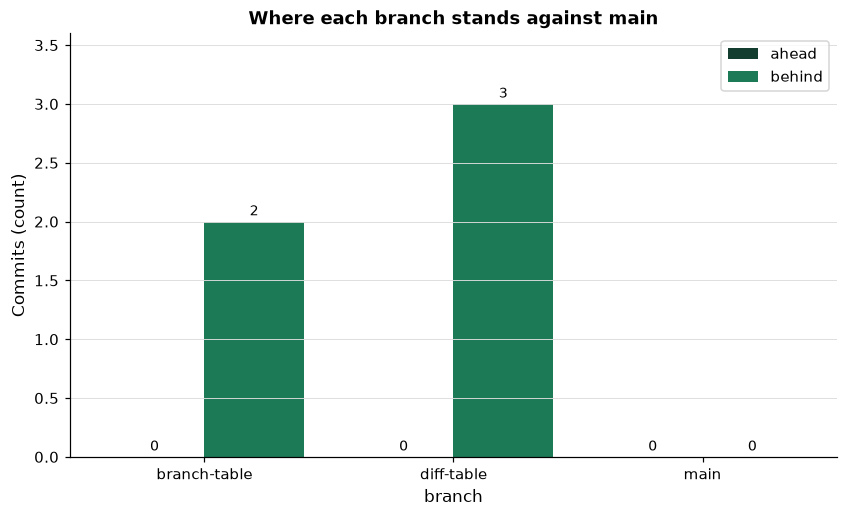

In [40]:
# ahead: commits the branch has that main lacks; behind: commits main has that the branch lacks
standing = deploykit.branch_table(work).set_index("branch")[["ahead", "behind"]]
display(plotkit.styled(standing, [], "Commits each branch is ahead of and behind main, after the two merges"))
ax = plotkit.bars(standing, "Where each branch stands against main", "Commits (count)", fmt="{:,.0f}")
ax.set_ylim(0, standing.to_numpy().max() * 1.2)
plt.show()

* Every ahead bar is zero: nothing on those branches is missing from `main`. The behind bars are how far each branch has fallen back.

* Every branch is `0` ahead: everything on them is on `main`. `branch-table` is 2 behind (the colleague's commit and the merge), `diff-table` 3 behind. A branch at 0 ahead is merged and can be deleted (section 2.8).

## 2.4 A Conflict on Purpose

Git merged the last two sides alone because they touched different files. When two branches change the **same lines**, Git stops and asks you: a **conflict**. The commonest one on a desk is two people adding a function at the end of the same file.

Q. Start the third function's branch from where `main` was before `branch_table` arrived, as if you had begun it this morning: `switch -c conflict-files diff-table` starts the branch at `diff-table`'s commit. Add `conflict_files` and its test, and commit.

In [41]:
# a branch can start from any commit, branch, or tag: here, diff-table's last commit
!git -C "{work}" switch -q -c conflict-files diff-table

In [42]:
%%writefile -a deploykit.py


def conflict_files(folder) -> list[str]:
    """The files a merge left in conflict, which you must read and resolve before you commit.

    Input: folder, the repository, in the middle of a merge that stopped.
    Output: the file names Git lists as unmerged (git diff --name-only --diff-filter=U), sorted; empty when there
    is no conflict.
    """
    return sorted(run_git(folder, "diff", "--name-only", "--diff-filter=U").split())

Appending to deploykit.py


In [43]:
%%writefile -a test_deploykit.py


def test_conflict_files_lists_unmerged(tmp_path):
    make_repo(tmp_path)
    deploykit.run_git(tmp_path, "switch", "-q", "-c", "theirs")
    commit(tmp_path, "notes.txt", "one\nTWO\nthree\n", "Upper case")
    deploykit.run_git(tmp_path, "switch", "-q", "main")
    commit(tmp_path, "notes.txt", "one\n2\nthree\n", "Digit")
    assert deploykit.conflict_files(tmp_path) == []
    with pytest.raises(RuntimeError, match="merge"):
        deploykit.run_git(tmp_path, "merge", "-q", "theirs")
    assert deploykit.conflict_files(tmp_path) == ["notes.txt"]

Appending to test_deploykit.py


In [44]:
importlib.reload(deploykit)
print(f"conflict_files in deploykit: {hasattr(deploykit, 'conflict_files')}")

conflict_files in deploykit: True


In [45]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_deploykit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........                                                                [100%]
9 passed in 1.95s



In [46]:
!git -C "{work}" add deploykit.py test_deploykit.py
!git -C "{work}" commit -q -m "Add conflict_files, with its test"

* `conflict_files(folder)` lists the files a merge left in conflict (`git diff --name-only --diff-filter=U`), sorted; an empty list when there is none. `9 passed` on this branch, which has `diff_table` and `conflict_files` but not `branch_table`.

Q. Bring `main` into the branch, the way you update a pull request whose branch is behind. What does Git say?

In [47]:
!git -C "{work}" merge main

Auto-merging deploykit.py
CONFLICT (content): Merge conflict in deploykit.py
Auto-merging test_deploykit.py
CONFLICT (content): Merge conflict in test_deploykit.py
Automatic merge failed; fix conflicts and then commit the result.


Q. Which files are in conflict?

In [48]:
# deploykit.py on disk now holds conflict markers; the module imported above is still in memory
print(deploykit.conflict_files(work))

['deploykit.py', 'test_deploykit.py']


* Both files. Git stopped before committing anything: the merge is half done, and the files on disk hold both versions of the disputed lines, between markers.

Q. Read both sides: show each file's conflict markers and the functions between them, with their line numbers.

In [49]:
for name in deploykit.conflict_files(work):
    lines = (work / name).read_text(encoding="utf-8").splitlines()
    start = next(n for n, line in enumerate(lines) if line.startswith("<<<<<<<"))
    print(name)
    for number, line in enumerate(lines[start:], start=start + 1):
        if line.startswith(("<<<<<<<", "=======", ">>>>>>>", "def ")):
            print(f"  {number:4}  {line}")

deploykit.py
   188  <<<<<<< HEAD
   189  def conflict_files(folder) -> list[str]:
   197  =======
   198  def branch_table(folder):
   213  >>>>>>> main
test_deploykit.py
   109  <<<<<<< HEAD
   110  def test_conflict_files_lists_unmerged(tmp_path):
   120  =======
   121  def test_branch_table_ahead_behind(tmp_path):
   132  >>>>>>> main


* Between `<<<<<<< HEAD` and `=======` is **this branch's** side: `conflict_files` and its test. Between `=======` and `>>>>>>> main` is **main's** side: `branch_table` and its test. Both sides added a function after the same last line, so Git cannot know which goes first, or whether both should stay.
* Reading both sides settles it: they are two different functions, both reviewed, both wanted. Keep both, `main`'s first, since it is already deployed, then this branch's. In VS Code this is **Accept Both Changes** above the markers; here a cell does the same text edit.

Q. Resolve both files: keep both sides of each conflict region, `main`'s lines first.

In [50]:
import re

# the lines on each side of the conflict regions, counted before they are resolved
sides = {}
# a conflict region: this branch's lines (group 1), then main's lines (group 2), between Git's three markers
region = re.compile(r"<<<<<<< HEAD\n(.*?)=======\n(.*?)>>>>>>> main\n", re.S)
for name in ["deploykit.py", "test_deploykit.py"]:
    text = (work / name).read_text(encoding="utf-8")
    print(f"{name}: {len(region.findall(text))} conflict region")
    sides[name] = {"this branch's lines": sum(len(mine.splitlines()) for mine, _ in region.findall(text)),
                   "main's lines": sum(len(theirs.splitlines()) for _, theirs in region.findall(text))}
    # main's lines, two blank lines (the module's spacing between functions), then this branch's lines
    (work / name).write_text(region.sub(lambda m: m.group(2) + "\n\n" + m.group(1), text), encoding="utf-8")

deploykit.py: 1 conflict region
test_deploykit.py: 1 conflict region


Q. How many lines sit on each side of the conflicts?

,this branch's lines,main's lines
file,,
deploykit.py,8,15
test_deploykit.py,10,11


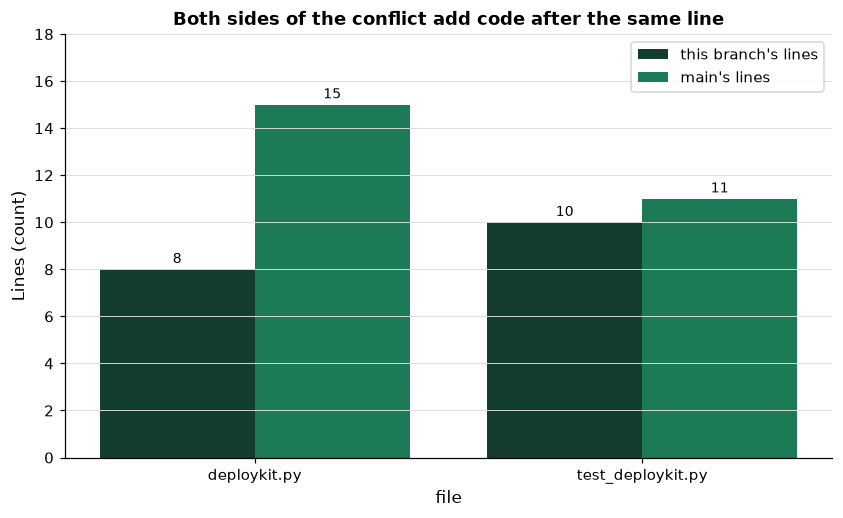

In [51]:
# the two sides of each conflict region, in lines, from the cell above
conflict_sides = pd.DataFrame(sides).T
conflict_sides.index.name = "file"
display(plotkit.styled(conflict_sides, [], "Lines on each side of the conflict regions, by file, before they were resolved"))
ax = plotkit.bars(conflict_sides, "Both sides of the conflict add code after the same line", "Lines (count)", fmt="{:,.0f}")
ax.set_ylim(0, conflict_sides.to_numpy().max() * 1.2)
plt.show()

* Each side adds between 8 and 15 lines in each file: neither is a one-line edit a reviewer could wave through. Keeping both is the resolution because both sides are wanted, not because one is shorter.

Q. Let the tests settle it: reload the module and run them. Is the merge finished?

In [52]:
importlib.reload(deploykit)
print(f"diff_table, branch_table, conflict_files: {[hasattr(deploykit, n) for n in ('diff_table', 'branch_table', 'conflict_files')]}")
print(f"still in conflict for Git: {deploykit.conflict_files(work)}")

diff_table, branch_table, conflict_files: [True, True, True]
still in conflict for Git: ['deploykit.py', 'test_deploykit.py']


In [53]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_deploykit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........                                                               [100%]
10 passed in 2.99s



* All three functions, and `10 passed`: every test of both sides runs. Had one side been dropped, its test would be missing or failing, and the count would say so.
* Git still lists both files: it only believes a file is resolved when you stage it with `git add`.

Q. Stage the resolved files, finish the merge, and draw the branch's history.

In [54]:
!git -C "{work}" add deploykit.py test_deploykit.py
!git -C "{work}" commit -q --no-edit
!git -C "{work}" log --graph --format=%s -6

*   Merge branch 'main' into conflict-files
|\  
| *   Merge remote-tracking branch 'origin/main'
| |\  
| | * Ignore server logs
| * | Add branch_table, with its test
| |/  
* / Add conflict_files, with its test
|/  
* Add diff_table, with its test


In [55]:
print(f"in conflict now: {deploykit.conflict_files(work)}")

in conflict now: []


* `[]`: nothing left in conflict. The branch now holds `main` and its own function: it is ready to merge back without a conflict.

## 2.5 A Pull Request Is a Branch Plus a Conversation

On GitHub, nobody merges into `main` of a shared repo by typing `git merge`. You push your branch and open a **pull request**: a page that asks to merge one branch into another, shows the diff, the commits, and the checks GitHub ran on them (day 3), and holds the conversation, the comments and the reviews, until someone merges it or closes it.

Q. Push `conflict-files`, as you would before opening its pull request.

In [56]:
# push the branch of the pull request
pushed = subprocess.run(["git", "-C", str(work), "push", "-u", "origin", "conflict-files"], capture_output=True,
                        text=True, check=True)
print(pushed.stdout + pushed.stderr)

branch 'conflict-files' set up to track 'origin/conflict-files'.
To remote.git
 * [new branch]      conflict-files -> conflict-files



* The same lines as section 2.2's push. On GitHub the remote adds a line of its own, below.

### On your own account: your first pull request

In your `pfi-bondmath` repo from day 1, make one small convention change on a branch: the README states the module's units. In PowerShell:

```powershell
Set-Location "$HOME\projects\pfi-bondmath"
git switch -c units-in-readme
```

Open `README.md` in VS Code and add this section at its end, then save:

```
## Conventions

The units of every function in `bondmath.py`, as its docstring states them:

* `coupon_pct` and `yield_pct` are annual rates in percent: 7.0 means 7 percent.
* Prices and accrued interest are per 100 of face.
* Durations are in years, convexity in years squared, spreads in basis points.
```

Scan the folder, commit, and push the branch:

```powershell
Set-Location "$HOME\projects\my_bondmath"
python -c "import deploykit; print(deploykit.public_scan(r'$HOME\projects\pfi-bondmath'))"
Set-Location "$HOME\projects\pfi-bondmath"
git commit -am "State the module's units in the README"
git push -u origin units-in-readme
```

Then open the pull request in your browser: on the repository's main page, choose `units-in-readme` in the **Branch** menu, click **Compare & pull request** in the yellow banner above the files, keep `main` as the base, give it a title and a description, and click **Create Pull Request** (docs.github.com/en/pull-requests/collaborating-with-pull-requests/proposing-changes-to-your-work-with-pull-requests/creating-a-pull-request, read 2026-10-12). With the GitHub CLI installed, `gh pr create` does the same from PowerShell, with `--base`, `--head`, `--title`, and `--body` (cli.github.com/manual/gh_pr_create, read 2026-10-12).

Q. What did Git print when the course pushed the same branch to its own throwaway repo, `pfi-deploy-demo`?

In [57]:
# recorded transcript: what the platform printed on the course's account, masked
deploykit.show_transcript(work / "course9_transcripts" / "day02" / "git_push_branch.txt", max_lines=12)

Recorded 2026-10-12 on the course's own account; account names, URLs, and ids masked to `student`.
> git push -u origin units-in-readme
branch 'units-in-readme' set up to track 'origin/units-in-readme'.

remote: 
remote: Create a pull request for 'units-in-readme' on GitHub by visiting:        
remote:      https://github.com/student/pfi-deploy-demo/pull/new/units-in-readme        
remote: 
To https://github.com/student/pfi-deploy-demo.git
 * [new branch]      units-in-readme -> units-in-readme


* The last two lines are section 2.2's: `To` the address, `* [new branch]`. Above them, lines starting `remote:` are GitHub's own, printed through Git: the address of a page that opens a pull request for the branch. The account name is masked to `student`.

Q. The course opened the pull request with `gh pr create`. What did it print, and what does `gh pr view` show?

In [58]:
# recorded transcript: what the platform printed on the course's account, masked
deploykit.show_transcript(work / "course9_transcripts" / "day02" / "gh_pr_create.txt", max_lines=6)

Recorded 2026-10-12 on the course's own account; account names, URLs, and ids masked to `student`.
> gh pr create --base main --head units-in-readme --title "State the module's units in the README" --body "Adds a Conventions section to the README, copied from the units in bondmath.py's docstring. No code changes."
https://github.com/student/pfi-deploy-demo/pull/1


In [59]:
# recorded transcript: what the platform printed on the course's account, masked
deploykit.show_transcript(work / "course9_transcripts" / "day02" / "gh_pr_view.txt", max_lines=20)

Recorded 2026-10-12 on the course's own account; account names, URLs, and ids masked to `student`.
> gh pr view 1
title:	State the module's units in the README
state:	OPEN
author:	student (student)
labels:	
assignees:	
reviewers:	
projects:	
milestone:	
number:	1
url:	https://github.com/student/pfi-deploy-demo/pull/1
additions:	1473
deletions:	1465
auto-merge:	disabled
--
Adds a Conventions section to the README, copied from the units in bondmath.py's docstring. No code changes.


* `gh pr create` printed one line: the pull request's address, number 1.
* `gh pr view` is the pull request as data: its title, `state: OPEN`, the author masked to `student` (the account name and the profile name both), its number, address, and the description last. Two numbers matter to a reviewer before anything else: **additions 1,473 and deletions 1,465**, for a change that added 8 lines to a README. Section 2.6 reads why.

## 2.6 Review by Diff

A review reads the change, not the description of it. Start with the numbers, then the lines.

Q. The course's own pull request was merged. What did the merge bring into `main`, file by file?

In [60]:
# recorded transcript: what the platform printed on the course's account, masked
deploykit.show_transcript(work / "course9_transcripts" / "day02" / "gh_pr_merge.txt", max_lines=16)

Recorded 2026-10-12 on the course's own account; account names, URLs, and ids masked to `student`.
> gh pr merge 1 --merge --delete-branch
Updating 36c77a1..0a270a8
Fast-forward
 .gitignore                       |    8 +-
 README.md                        |    8 +
 bondmath.py                      | 1144 +++++++++++++++++++-------------------
 bondmath_excel_reference.csv     |  614 ++++++++++----------
 bondmath_excel_reference_tvm.csv |  308 +++++-----
 test_bondmath.py                 |  856 ++++++++++++++--------------
 6 files changed, 1473 insertions(+), 1465 deletions(-)

From https://github.com/student/pfi-deploy-demo
 * branch            main       -> FETCH_HEAD
   36c77a1..0a270a8  main       -> origin/main


Q. Draw the diff stat: lines changed in each file of the merged pull request.

,lines changed
file,
.gitignore,8
README.md,8
bondmath.py,"1,144"
bondmath_excel_reference.csv,614
bondmath_excel_reference_tvm.csv,308
test_bondmath.py,856


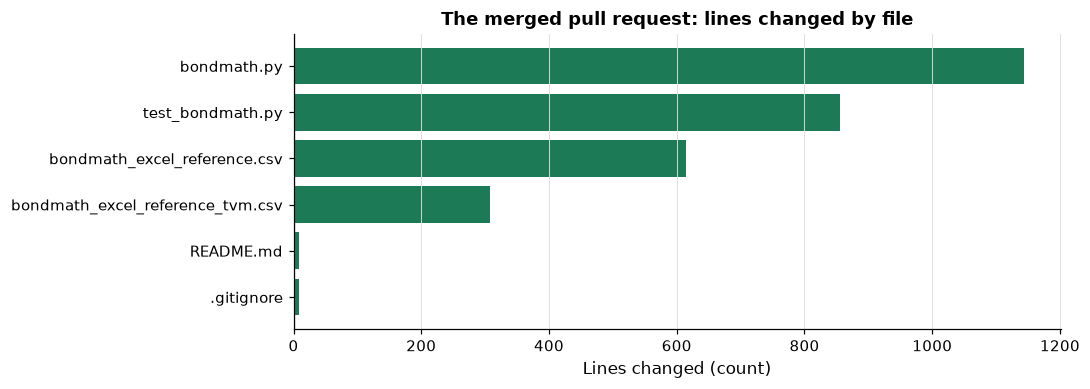

In [61]:
# the recorded transcript's diff stat, one line per file: "name | lines changed ++--"
body = (work / "course9_transcripts" / "day02" / "gh_pr_merge.txt").read_text(encoding="ascii").splitlines()[3:]
stat = {line.split("|")[0].strip(): int(line.split("|")[1].split()[0]) for line in body if " | " in line}
merged_stat = pd.DataFrame({"lines changed": stat})
merged_stat.index.name = "file"
display(plotkit.styled(merged_stat, [], "Lines changed per file by the merged pull request, from the recorded diff stat"))
ax = plotkit.importance_bars(merged_stat.index, merged_stat["lines changed"], "The merged pull request: lines changed by file",
                             xlabel="Lines changed (count)")
plt.show()

* One file, `README.md`, changed on purpose: 8 lines. The other five changed only in their line endings, and the diff stat counts every line they hold, from 8 in `.gitignore` to 1,144 in `bondmath.py`: the finding of the next section. Read this chart before you merge.

* `gh pr merge` merged on GitHub, deleted the branch there and in the clone, and brought the clone's `main` up to GitHub's new `main`: locally that last step is a `Fast-forward`.
* The table is the finding. `README.md`: 8 lines, the convention change. Every other file, 5 of them: about as many lines added as removed, `bondmath.py` 1,144 for its 572 lines. Nothing in them changed but the **line endings**. The machine that recorded this has Git's `core.autocrlf` setting on, which writes Windows line endings (CRLF) into the folder at checkout; the course's capture then switched that setting off inside the clone, so `commit -a` saw every line as changed and committed Windows endings into a repo whose files had Unix ones.
* A reviewer who reads the numbers stops this in a second; the course's recording merged it without that read. Two habits follow: read `diff_table` (or GitHub's file list) before you merge, and never change `core.autocrlf` in a repository you have already cloned. Day 3 adds a `.gitattributes` file, which fixes the endings in the repository itself.

Q. Now review a change before it merges. You asked an AI assistant to tidy `bondmath.future_value`, and it returned an edit. Put the edit on a branch of its own.

In [62]:
!git -C "{work}" switch -q -c ai-tidy main

In [63]:
# the edit as the assistant returned it: rate_pct renamed rate, and the default frequency changed from 2 to 1
text = (work / "bondmath.py").read_text(encoding="utf-8")
start, end = text.index("def future_value("), text.index("def present_value(")
before = text[start:end]
after = before.replace("rate_pct", "rate").replace("frequency: int = 2)", "frequency: int = 1)")
(work / "bondmath.py").write_text(text[:start] + after + text[end:], encoding="utf-8")
print(f"lines the edit changes in future_value: {sum(a != b for a, b in zip(before.splitlines(), after.splitlines()))}")

lines the edit changes in future_value: 4


In [64]:
!git -C "{work}" add bondmath.py
!git -C "{work}" commit -q -m "Tidy future_value"

Q. Review it. First the table, then every changed word.

In [65]:
print(deploykit.diff_table(work, "main", "ai-tidy").to_string(index=False))

       file  added  removed
bondmath.py      4        4

,added,removed
file,,
bondmath.py,4,4


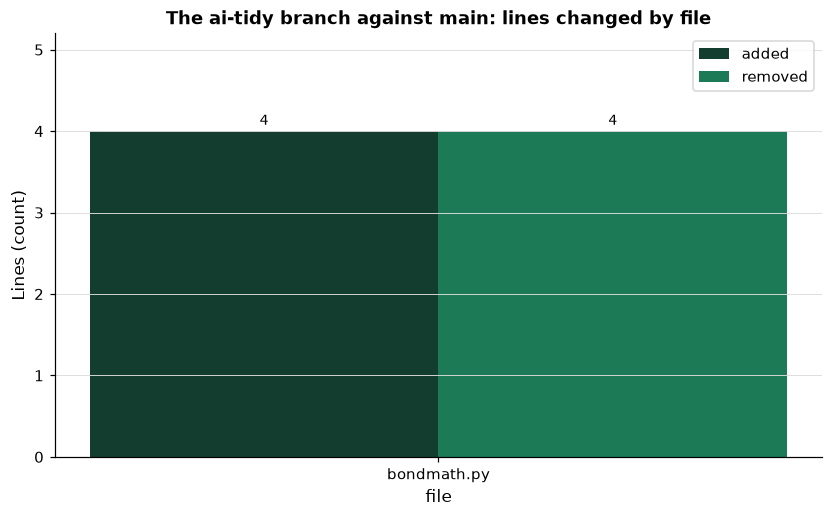

In [66]:
# the same table drawn: a small change by its line count
ai_diff = deploykit.diff_table(work, "main", "ai-tidy").set_index("file")
display(plotkit.styled(ai_diff, [], "Lines the ai-tidy branch changes against main, by file"))
ax = plotkit.bars(ai_diff, "The ai-tidy branch against main: lines changed by file", "Lines (count)", fmt="{:,.0f}")
ax.set_ylim(0, ai_diff.to_numpy().max() * 1.3)
plt.show()

* Four lines added and four removed in one file: a small change by the count. The next cell reads the words, because the count cannot see that it renames a parameter and changes a default.

In [67]:
# --word-diff marks removed words [-like this-] and added words {+like this+}, inside each line
!git -C "{work}" diff --word-diff main ai-tidy

diff --git a/bondmath.py b/bondmath.py
index d9098fc..ab14dd0 100644
--- a/bondmath.py
+++ b/bondmath.py
@@ -14,18 +14,18 @@ import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, [-rate_pct:-]{+rate:+} float, years: float, frequency: int = [-2)-]{+1)+} -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), [-rate_pct-]{+rate+} in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: [-=FV(rate_pct/100/frequency,-]{+=FV(rate/100/frequency,+} frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = [-rate_pct-]{+rate+} / 100 / frequency
    

Q. What do the two changes do to code that already uses `future_value`? Run the branch's `bondmath` in a fresh Python, and the same line with `main`'s.

In [68]:
# a fresh Python in the work folder imports the branch's bondmath.py; the notebook's bondmath is main's
lines = ("import bondmath\n"
         "print(f'branch: future_value(100, 5.0, 10) = {bondmath.future_value(100, 5.0, 10):.4f}')\n"
         "try:\n"
         "    bondmath.future_value(100, rate_pct=5.0, years=10)\n"
         "except TypeError as error:\n"
         "    print(f'branch: future_value(100, rate_pct=5.0, years=10) -> TypeError: {error}')\n")
ran = subprocess.run([sys.executable, "-c", lines], cwd=work, capture_output=True, text=True, check=True)
print(ran.stdout.strip())
print(f"main:   future_value(100, 5.0, 10) = {bondmath.future_value(100, 5.0, 10):.4f}")

branch: future_value(100, 5.0, 10) = 162.8895
branch: future_value(100, rate_pct=5.0, years=10) -> TypeError: future_value() got an unexpected keyword argument 'rate_pct'
main:   future_value(100, 5.0, 10) = 163.8616


* One file, four lines: the table says the edit is small. The word diff says what it is: `rate_pct` became `rate` four times, and the default `frequency` became 1.
* Two silent breaks. Code that leaves `frequency` out now compounds once a year: 100 at 5% for 10 years grows to 162.8895 instead of 163.8616, with no error anywhere. Code that names the argument, `rate_pct=5.0`, now fails with `TypeError`. And `rate` drops the unit from the name, which the module's own docstring rules out.
* The review comment, written as a sentence on the line it is about: *"bondmath.py line 17: please keep `rate_pct` and `frequency: int = 2`. The new default changes every result that relies on it (future_value(100, 5.0, 10) goes from 163.8616 to 162.8895), and the rename breaks code that passes rate_pct by name."* The branch is not merged. Section 2.8 deletes it.

Q. Leave the branch: back to `main`.

In [69]:
!git -C "{work}" switch -q main
!git -C "{work}" status -sb

## main...origin/main
?? plotkit.py


* `main`'s `bondmath.py` is back in the folder, unchanged. A branch that is reviewed and rejected costs `main` nothing.

## 2.7 Three Ways to Merge

GitHub's merge button offers three methods (docs.github.com/en/repositories/configuring-branches-and-merges-in-your-repository/configuring-pull-request-merges/about-merge-methods-on-github, read 2026-10-12):

| Method | What GitHub's page says | In `git` terms |
|---|---|---|
| Merge commit | "all commits from the feature branch are added to the base branch in a merge commit" | `merge --no-ff`: section 2.3's shape, every time |
| Squash | "the pull request's commits are squashed into a single commit" | `merge --squash`, then one commit |
| Rebase | "all commits from the topic branch (or head branch) are added onto the base branch individually without a merge commit" | the branch's commits copied onto `main`, one by one |

**The course's choice for your own pull requests is squash**: one pull request becomes one commit on `main`, with one message, however many small commits the branch needed (here: the function, then the merge that resolved the conflict). `main`'s history then reads one line per change, which is what a deploy log points at. The course's recorded pull request in section 2.5 was merged with a merge commit (`gh pr merge --merge`), so its branch's commit is on `main` beside the merge.

Q. Squash `conflict-files` into `main`: the day's module commit.

In [70]:
# --squash stages the branch's whole change as one, and stops before committing
!git -C "{work}" merge --squash -q conflict-files
!git -C "{work}" status --short

Squash commit -- not updating HEAD


M  deploykit.py
M  test_deploykit.py
?? plotkit.py


In [71]:
!git -C "{work}" commit -q -m "deploykit day 2: conflict_files, squashed from its branch; 10 tests"
!git -C "{work}" log --graph --format=%s -5

* deploykit day 2: conflict_files, squashed from its branch; 10 tests
*   Merge remote-tracking branch 'origin/main'
|\  
| * Ignore server logs
* | Add branch_table, with its test
|/  
* Add diff_table, with its test


In [72]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_deploykit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........                                                               [100%]
10 passed in 2.89s



* `--squash` staged the branch's whole change, both files, and stopped: you write the one commit message. The graph has no merge line for it: `main` gained a single ordinary commit on top of section 2.3's merge.
* `10 passed` on `main`: the day's three functions and their tests.

## 2.8 Deleting Merged Branches

A merged branch has done its job. Deleting it keeps the list short, so that every branch you see is work in progress.

Q. Where does every branch stand against `main` now?

In [73]:
print(deploykit.branch_table(work).to_string(index=False))

        branch                                                        last_subject  ahead  behind
       ai-tidy                                                   Tidy future_value      1       1
  branch-table                                     Add branch_table, with its test      0       3
conflict-files                             Merge branch 'main' into conflict-files      2       1
    diff-table                                       Add diff_table, with its test      0       4
          main deploykit day 2: conflict_files, squashed from its branch; 10 tests      0       0


,ahead,behind
branch,,
ai-tidy,1,1
branch-table,0,3
conflict-files,2,1
diff-table,0,4
main,0,0


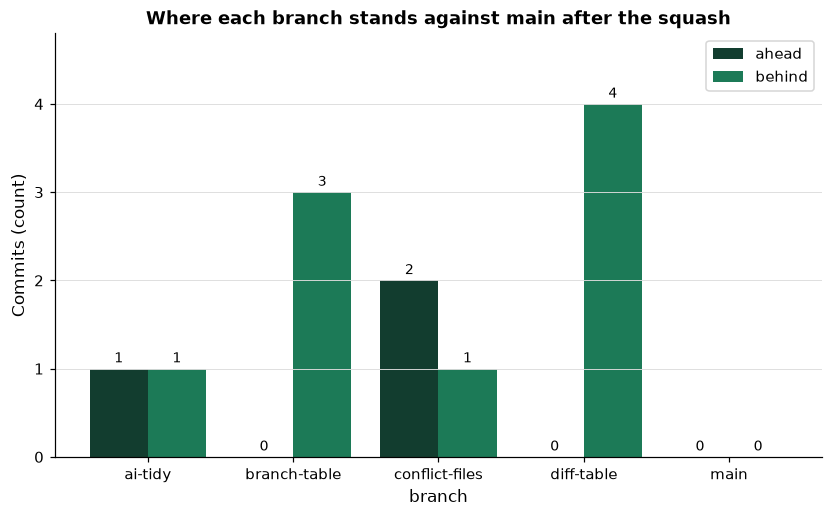

In [74]:
# the same view as section 2.3, after the squash merge
standing_after = deploykit.branch_table(work).set_index("branch")[["ahead", "behind"]]
display(plotkit.styled(standing_after, [], "Commits each branch is ahead of and behind main, after the squash merge"))
ax = plotkit.bars(standing_after, "Where each branch stands against main after the squash", "Commits (count)", fmt="{:,.0f}")
ax.set_ylim(0, standing_after.to_numpy().max() * 1.2)
plt.show()

* `diff-table` and `branch-table`: 0 ahead, merged. `ai-tidy`: 1 ahead, the rejected edit. `conflict-files`: 2 ahead, although every line of it is on `main`: a squash makes a **new** commit, so the branch's own commits never reached `main`, only their sum.

Q. First the remote: delete the two branches you pushed, and let the colleague catch up.

In [75]:
deleted = subprocess.run(["git", "-C", str(work), "push", "origin", "--delete", "diff-table", "conflict-files"],
                         capture_output=True, text=True, check=True)
print(deleted.stdout + deleted.stderr)
# the colleague fetches; --prune drops their copies of branches the remote no longer has
deploykit.run_git(colleague, "fetch", "-q", "--prune")
print(deploykit.run_git(colleague, "branch", "-r"))

To remote.git
 - [deleted]         conflict-files
 - [deleted]         diff-table



  origin/HEAD -> origin/main
  origin/main



* `- [deleted]` for each. On GitHub, `gh pr merge --delete-branch` did the same for the course's pull request.
* The colleague's list holds `origin/main` only (and `origin/HEAD`, which a clone records as the remote's default branch). Without `--prune`, a fetch keeps the names of branches that are gone.

Q. Now your own copies. Delete the two merged branches, then try to delete `conflict-files` the same way.

In [76]:
# -d deletes a branch only when its commits are on the branch you are on
!git -C "{work}" branch -d -q diff-table branch-table

In [77]:
# -d refuses a branch whose commits are not on main: after a squash merge, Git cannot tell it was merged
try:
    deploykit.run_git(work, "branch", "-d", "conflict-files")
except RuntimeError as refused:
    print(f"refused: {refused}")

refused: git branch -d conflict-files failed: error: the branch 'conflict-files' is not fully merged
hint: If you are sure you want to delete it, run 'git branch -D conflict-files'
hint: Disable this message with "git config set advice.forceDeleteBranch false"


* Refused: `not fully merged`. Git checks commits, not content, and a squash leaves the branch's commits off `main`. You know it was merged, because you just squashed it, so `-D` deletes it anyway. The same `-D` deletes `ai-tidy`, which is unmerged on purpose. Use `-D` only when you know why `-d` refused.
* The order mattered. While `conflict-files` still had its copy on the remote, `-d` would have deleted it with only a warning, because its commits were on that copy; with the remote's copy gone, only `main` counts.

In [78]:
!git -C "{work}" branch -D -q conflict-files ai-tidy
!git -C "{work}" branch

* main


* `* main`, alone: everything the day made is on it, and nothing unfinished is left.

## Excel Side by Side

None today. Excel has no branch, no merge, and no conflict to resolve: two people editing copies of one workbook end up with two workbooks, and comparing them is a job done by eye or by a separate tool, not by the file's own history. Week 3 brings Excel back, where it reads what a service logs.

## Save the Day with Git

The day's module commit was section 2.7's squash. Now publish it.

Q. Push `main`, bring the colleague level, and show what the day's last commit holds.

In [79]:
!git -C "{work}" push -q
!git -C "{work}" status -sb
!git -C "{work}" show --stat --format=%s HEAD

## main...origin/main
?? plotkit.py


deploykit day 2: conflict_files, squashed from its branch; 10 tests

 deploykit.py      | 10 ++++++++++
 test_deploykit.py | 12 ++++++++++++
 2 files changed, 22 insertions(+)


In [80]:
deploykit.run_git(colleague, "pull", "-q", "--ff-only")
print(deploykit.run_git(colleague, "log", "--format=%s", "-1"))
print(deploykit.run_git(colleague, "status", "-sb"))

deploykit day 2: conflict_files, squashed from its branch; 10 tests

## main...origin/main



* The squash commit holds both files, `deploykit.py` and `test_deploykit.py`: the third function and its test, one change, one commit. The colleague has it, level with `origin/main`.

## Bring It Home

In your own `my_bondmath`, do the day the course's way: on a branch, merged by squash. Open a PowerShell terminal in VS Code, with the course environment active.

**Step 1.** A branch for the day:

```powershell
Set-Location "$HOME\projects\my_bondmath"
git switch -c day2
```

**Step 2.** Paste the code of today's three `%%writefile -a deploykit.py` cells (sections 2.2, 2.3, and 2.4), without their first lines, at the end of `deploykit.py`, in that order; then the three `%%writefile -a test_deploykit.py` cells at the end of `test_deploykit.py`. Run the tests:

```powershell
python -m pytest -q test_deploykit.py
```

The last line says `10 passed`.

**Step 3.** Commit on the branch, then squash it into `main` and delete it:

```powershell
git add deploykit.py test_deploykit.py
git commit -m "deploykit day 2: diff_table, branch_table, conflict_files"
git switch main
git merge --squash day2
git commit -m "deploykit day 2: diff_table, branch_table, conflict_files, 10 tests"
git branch -D day2
```

`-D`, because a squash leaves the branch's own commit off `main` (section 2.8).

**Step 4.** Your first pull request, on `pfi-bondmath`, as in section 2.5. Read its file list before you merge it: one file, `README.md`, and only added lines. Merge it with squash (`gh pr merge --squash --delete-branch`, or the merge method of the same name on the pull request's page), then bring your folder up to date with `git switch main` and `git pull --ff-only`.

**In Colab**, the notebook runs as it is. The PowerShell steps are for your own machine.

## You Can Now

* Say why `main` is what is deployed, and do your work on a branch beside it.
* Push a branch, and read what it changes with `diff_table` before anyone merges it.
* Tell a fast-forward from a merge commit, and get past a rejected push: fetch, merge, push.
* Resolve a conflict by reading both sides, keeping what both meant, and letting the tests settle it.
* Open a pull request on GitHub, and read one with `gh pr view`.
* Review a change by its numbers and its word diff, and write the comment as a sentence on a line.
* Squash a branch into one commit, and delete merged branches here and on the remote.

Next, day 3: GitHub Actions runs your tests on a Linux machine on every push and every pull request.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It defines `check`, a small function that marks your answers, and `day_conflict`, which rebuilds today's conflict in a folder of its own for the AI check.

In [81]:
import re


# the exercises work in folders of their own inside the work folder, so today's repository stays as it is
def day_conflict(folder):
    """Today's conflict, rebuilt in a new repository: from a common start, main adds branch_table and the branch
    review adds conflict_files, each with its test, at the end of the same two files; then review merges main."""
    folder = Path(folder)
    folder.mkdir()
    deploykit.run_git(folder, "init", "-q", "-b", "main")
    for setting in (["user.name", "Course Student"], ["user.email", "student@example.com"],
                    ["core.autocrlf", "false"], ["commit.gpgsign", "false"]):
        deploykit.run_git(folder, "config", *setting)
    versions = {}
    for name, first, second in [("deploykit.py", "def branch_table", "def conflict_files"),
                                ("test_deploykit.py", "def test_branch_table", "def test_conflict_files")]:
        text = deploykit.run_git(work, "show", f"HEAD:{name}")
        a, b = text.index("\n\n\n" + first), text.index("\n\n\n" + second)
        # the start, main's version, and the review branch's version
        versions[name] = (text[:a] + "\n", text[:b] + "\n", text[:a] + text[b:])

    def save(which, message):
        for name, texts in versions.items():
            (folder / name).write_text(texts[which], encoding="utf-8")
        deploykit.run_git(folder, "add", *versions)
        deploykit.run_git(folder, "commit", "-q", "-m", message)

    save(0, "Start: diff_table")
    deploykit.run_git(folder, "switch", "-q", "-c", "review")
    save(2, "Add conflict_files, reviewed")
    deploykit.run_git(folder, "switch", "-q", "main")
    save(1, "Add branch_table")
    deploykit.run_git(folder, "switch", "-q", "review")
    # the merge stops on the conflict: Git exits with 1, which is expected here
    subprocess.run(["git", "-C", str(folder), "merge", "-q", "main"], capture_output=True, text=True)


print(f"branches of the work folder: {deploykit.run_git(work, 'branch', '--format=%(refname:short)').split()}")

def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

branches of the work folder: ['main']


### Exercise 1

Q. A second conflict, in the tests file only. The cell below clones your remote into `ex1` and makes two branches from `main`, `ex1-first` and `ex1-second`, each adding one test at the end of `test_deploykit.py`. On `ex1-first`, merge `ex1-second` with `deploykit.run_git(ex1, ...)` (Git stops, and `run_git` raises, so catch the `RuntimeError`), store `deploykit.conflict_files(ex1)` in **ex1_files**, then resolve it as in section 2.4, keeping both tests, commit, and run the tests in `ex1`.

In [82]:
# a clone of your remote, with two branches that each add one test at the end of test_deploykit.py
ex1 = work / "ex1"
deploykit.run_git(work, "clone", "-q", "remote.git", "ex1")
for setting in (["user.name", "Course Student"], ["user.email", "student@example.com"], ["core.autocrlf", "false"],
                ["commit.gpgsign", "false"]):
    deploykit.run_git(ex1, "config", *setting)
new_tests = {
    'ex1-first': '\n\ndef test_diff_table_empty_for_the_same_commit(tmp_path):\n    make_repo(tmp_path)\n    assert deploykit.diff_table(tmp_path, "main", "main").empty\n',
    'ex1-second': '\n\ndef test_conflict_files_empty_without_a_merge(tmp_path):\n    make_repo(tmp_path)\n    assert deploykit.conflict_files(tmp_path) == []\n',
}
for branch, test in new_tests.items():
    deploykit.run_git(ex1, "switch", "-q", "-c", branch, "main")
    with open(ex1 / "test_deploykit.py", "a", encoding="utf-8") as f:
        f.write(test)
    deploykit.run_git(ex1, "commit", "-q", "-am", f"Add a test on {branch}")
print(deploykit.branch_table(ex1).to_string(index=False))

    branch                                                        last_subject  ahead  behind
 ex1-first                                             Add a test on ex1-first      1       0
ex1-second                                            Add a test on ex1-second      1       0
      main deploykit day 2: conflict_files, squashed from its branch; 10 tests      0       0


In [83]:
# merge ex1-second into ex1-first, list the files in conflict, then resolve, commit, and run the tests
ex1_files = ...

In [84]:
check("Exercise 1 the files in conflict", ex1_files, ["test_deploykit.py"])

Exercise 1 the files in conflict: not attempted yet


### Exercise 2

Q. A branch that is behind `main`. In the work folder, make a branch `stale` where `main` is now (`git branch stale`, which does not switch to it), then add the line `*.log` to `.gitignore` on `main` and commit it. Store the `ahead` and `behind` of `stale` from `deploykit.branch_table(work)`, as a tuple of two whole numbers, in **ex2_row**.

In [85]:
ex2_row = ...

In [86]:
check("Exercise 2 stale, ahead and behind", ex2_row, (0, 1))

Exercise 2 stale, ahead and behind: not attempted yet


### Exercise 3

Q. Add a function to your module. `merged_branches(folder)` returns the local branches whose every commit is already on `main`, sorted, without `main` itself (`git branch --merged main` lists them). Write the docstring first, then `test_merged_branches`, which makes a repository in `tmp_path` with one branch that has nothing new and one that has a commit of its own. Run pytest, reload the module, and store `deploykit.merged_branches(work)` in **ex3_names**.

Write the function in the cell that starts with `%%writefile -a deploykit.py` and the test in the one that starts with `%%writefile -a test_deploykit.py`, and run each of those cells once.

In [87]:
%%writefile -a deploykit.py


# Exercise 3: write merged_branches(folder) below this line

Appending to deploykit.py


In [88]:
%%writefile -a test_deploykit.py


# Exercise 3: write test_merged_branches(tmp_path) below this line

Appending to test_deploykit.py


In [89]:
# run pytest, reload the module, then list the merged branches of the work folder
ex3_names = ...

In [90]:
check("Exercise 3 the merged branches", ex3_names, ["stale"])

Exercise 3 the merged branches: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for a helper that finishes a merge when a conflict stops it, and give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Finish a merge that stopped because both sides added code at the same place in the same files.

    Input: folder, a repository in the middle of a merge: the current branch is the reviewed one, and the other
    side is the branch being merged into it. For each file Git lists as in conflict, keep both sides, the merged
    branch's lines first and then the current branch's, with the conflict markers removed; stage the file; then
    commit the merge. Output: the files resolved, sorted. Convention: never drops either side; run the tests after.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, finishes the merge, and contains one bug.

In [91]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def resolve_conflicts(folder):
    """Finish a stopped merge: resolve every conflicted file, stage it, and commit the merge."""
    files = deploykit.conflict_files(folder)
    for name in files:
        # take the incoming side of the file, so the merge can finish
        deploykit.run_git(folder, "checkout", "--theirs", name)
        deploykit.run_git(folder, "add", name)
    deploykit.run_git(folder, "commit", "-q", "--no-edit")
    return files

Q. Before you run the test: `day_conflict` stops a merge on the branch `review`, whose side holds `conflict_files`, while `main`'s side holds `branch_table`. Which functions will `deploykit.py` hold after `resolve_conflicts`, and would its merge commit look any different from a correct one in `git log`?

Q. Test the function against its docstring before you trust it: both functions must be in the file, and the tests must pass.

In [92]:
# the test, written from the docstring before the code is trusted
# today's conflict in a folder of its own: main added branch_table, the reviewed branch review added conflict_files
planted = work / "ai_check"
day_conflict(planted)
print(f"in conflict: {deploykit.conflict_files(planted)}")
resolved = resolve_conflicts(planted)
text = (planted / "deploykit.py").read_text(encoding="utf-8")
kept = [name for name in ("def branch_table", "def conflict_files") if name in text]
assert len(kept) == 2, f"resolve_conflicts kept {len(kept)} of the 2 functions the two sides added: {kept}"
tests = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no",
                        "test_deploykit.py"],
                       cwd=planted, capture_output=True, text=True)
assert tests.returncode == 0, tests.stdout[-500:]
print(f"resolved: {resolved}; both functions kept; the tests: {tests.stdout.strip().splitlines()[-1]}")

in conflict: ['deploykit.py', 'test_deploykit.py']


AssertionError: resolve_conflicts kept 1 of the 2 functions the two sides added: ['def branch_table']

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the number of functions the fixed version keeps, of the two, in **ex4_kept**.

In [93]:
# fix the function above and run the test again, then store the answer
ex4_kept = ...

In [94]:
check("Exercise 4 the functions kept", ex4_kept, 2)

Exercise 4 the functions kept: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```